<div style="border-left:4px solid #3D6FB0;padding:6px 0 8px 16px;"><div style="opacity:.72;font-size:12px;letter-spacing:1.4px;">DATOS MASIVOS II · PRÁCTICA</div><div style="color:#3D6FB0;font-size:27px;font-weight:700;margin-top:4px;">PageRank y HITS en el grafo de enlaces de Wikipedia</div><div style="opacity:.72;font-size:14px;margin-top:6px;">Cómo medir la importancia de un artículo con sus enlaces.</div><div style="opacity:.72;font-size:14px;margin-top:6px;margin-bottom:10px;">Equipo Tres: Castrillo Cruz Karen Arlet, Ramos González Nadia, Zamora Antiga Ángel Javier.</div><img src="https://mmss.iimas.unam.mx/dmmss/wp-content/uploads/2026/02/cropped-LogoUNAM_IIMAS_Negro50-scaled-2.png" width="200"/></div>

### Objetivo

Queremos saber qué artículos de la Wikipedia en inglés son importantes usando solo sus enlaces. Si muchos artículos enlazan a uno, ese artículo importa, y más todavía si quienes lo enlazan también importan.

Usamos dos algoritmos que entienden "importante" de forma distinta:

- **PageRank** imagina a un lector que salta de enlace en enlace. Un artículo es importante si el lector pasa mucho tiempo en él.
- **HITS** separa dos papeles. Una **autoridad** es un artículo al que apuntan las páginas que reúnen buen material. Un **hub** es una página que reúne enlaces a buenas autoridades.

### El modelo

- **Nodo:** un artículo. Hay 7,249,099.
- **Arista:** $i \to j$ si el texto de $i$ tiene un enlace a $j$. Hay 236,242,098.
- **Peso:** ninguno. Da lo mismo enlazar una vez que diez, porque nos interesa si existe la relación.
- **Dirección:** sí importa. Que $i$ enlace a $j$ no significa que $j$ enlace a $i$.

Con siete millones de nodos no se puede usar `networkx` para el cálculo completo, porque no cabe en memoria. Por eso los algoritmos se programan con matrices dispersas de `scipy`, y `networkx` solo se usa para comprobar los resultados en un grafo pequeño.

### Contenido

1. Datos.
2. Matriz de adyacencia.
3. Matriz de transición y estructura de la red.
4. PageRank.
5. HITS.
6. Comprobaciones.

In [1]:
# Librerías, rutas, paleta y funciones auxiliares de estilo
import re
import sys
import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import pyarrow.dataset as ds
import pyarrow.parquet as pq
import scipy.sparse as sp
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from scipy.sparse.csgraph import breadth_first_order, connected_components
from scipy.stats import spearmanr
from IPython.display import display

sys.path.insert(0, "..")   # registro.py está en la carpeta Wikipedia/
import registro as reg

NB = "02_pagerank_hits"    # carpeta de resultados: data/resultados/02_pagerank_hits/

%matplotlib inline
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 80)

GRAFO = Path("..") / "data" / "grafo"
ARCHIVO_MATRIZ = GRAFO / "adyacencia.npz"
ARCHIVO_PUNTAJES = GRAFO / "puntajes.parquet"

# Paleta única del notebook: azul principal, rojo de acento y grises neutros
AZUL, ROJO = "#3D6FB0", "#B03D3D"
GRIS, GRIS_CLARO, TINTA = "#8C8C8C", "#EEF1F6", "#333333"
# Escala secuencial de un solo tono (azules) para conteos y densidades; vacío = blanco
CMAP_SEC = LinearSegmentedColormap.from_list("azules", plt.cm.Blues(np.linspace(0.22, 1, 256)))
CMAP_SEC.set_bad("white")

plt.rcParams.update({
    "figure.dpi": 100, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.edgecolor": "#999999", "axes.labelcolor": TINTA,
    "xtick.color": TINTA, "ytick.color": TINTA, "legend.frameon": False,
})


def estilo_ejes(ax, titulo=None, xlabel=None, ylabel=None, rejilla="y"):
    """
    Aplica el estilo común a unos ejes de matplotlib.

    Parámetros
    ----------
    ax : matplotlib.axes.Axes
        Ejes a formatear.
    titulo, xlabel, ylabel : str, opcional
        Título y etiquetas de los ejes (con unidades).
    rejilla : {"x", "y", "both", None}
        Eje sobre el que se dibuja una rejilla tenue.
    """
    if titulo:
        ax.set_title(titulo)
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    ax.spines[["top", "right"]].set_visible(False)
    if rejilla:
        ax.grid(axis=rejilla, color="#DDDDDD", linewidth=0.6)
        ax.set_axisbelow(True)


def pct(x, dec=2):
    """Formatea una proporción como porcentaje con espacio antes del símbolo."""
    return f"{100 * x:,.{dec}f} %"


def tamano(nbytes):
    """Formatea un número de bytes en MB o GB decimales (10⁶ y 10⁹ bytes)."""
    return f"{nbytes / 1e9:,.2f} GB" if nbytes >= 1e9 else f"{nbytes / 1e6:,.1f} MB"

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · DATOS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">1. Datos</span></div>

Cargamos los nodos y las aristas que dejó listos el notebook 1. También marcamos por su título dos tipos de página que usaremos más adelante: las **listas** (`List of…`, `Outline of…`) y las **cronologías** (`1982`, `May 1982`, `2025 in the United States`).

In [2]:
# Carga de nodos y aristas, traducción de page_id a índice y marcas por título
inicio = time.time()
nodos = pq.read_table(GRAFO / "nodos").to_pandas().sort_values("idx").reset_index(drop=True)
nodos.index.name = "indice"
n = len(nodos)
ids = nodos["id"].to_numpy()

tabla = ds.dataset(GRAFO / "aristas").to_table()
posicion = np.full(ids.max() + 1, -1, dtype=np.int32)
posicion[ids] = np.arange(n, dtype=np.int32)
origen = posicion[tabla.column("src").to_numpy()]
destino = posicion[tabla.column("dst").to_numpy()]
m = len(origen)
del tabla

MESES = "January|February|March|April|May|June|July|August|September|October|November|December"
nodos["es_lista"] = nodos["title"].str.match(r"^(Lists? of|Index of|Outline of|Timeline of) ")
nodos["es_cronologia"] = nodos["title"].str.fullmatch(
    rf"(\d{{1,4}}s?|\d{{1,2}}(st|nd|rd|th) (century|millennium))( BC| AD| BCE| CE)?|({MESES}) \d{{3,4}}|\d{{3,4}} in .+")

# Comprobaciones: índice denso ordenado por page_id, aristas válidas, sin autolazos ni duplicados
assert nodos["id"].is_unique and np.all(np.diff(ids) > 0)
assert np.array_equal(nodos["idx"].to_numpy(), np.arange(n))
assert (origen >= 0).all() and (destino >= 0).all() and not (origen == destino).any()
assert len(np.unique(origen.astype(np.int64) * n + destino)) == m

resumen = pd.Series({
    "Nodos (artículos)": f"{n:,}",
    "Aristas (enlaces i → j)": f"{m:,}",
    "Páginas de desambiguación (is_disambig)": f"{nodos['is_disambig'].sum():,} ({pct(nodos['is_disambig'].mean())})",
    "Listas, índices y cronologías (es_lista)": f"{nodos['es_lista'].sum():,} ({pct(nodos['es_lista'].mean())})",
    "Páginas de año, mes o «AAAA in …» (es_cronologia)": f"{nodos['es_cronologia'].sum():,} ({pct(nodos['es_cronologia'].mean())})",
    "Nodos colgantes (k_out = 0)": f"{(nodos['grado_salida'] == 0).sum():,}",
    "Nodos sin enlaces de entrada (k_in = 0)": f"{(nodos['grado_entrada'] == 0).sum():,}",
}, name="Valor").rename_axis("Métrica").to_frame()
display(resumen)
print("Ejemplos de es_cronologia:", nodos.loc[nodos["es_cronologia"], "title"].sample(8, random_state=42).tolist())
reg.registrar_paso("02.1", inicio, [reg.guardar_tabla(resumen, "01_resumen_datos", NB)], f"{n:,} nodos y {m:,} aristas")

,Valor
Métrica,
Nodos (artículos),"7,249,099"
Aristas (enlaces i → j),"236,242,098"
Páginas de desambiguación (is_disambig),"369,725 (5.10 %)"
"Listas, índices y cronologías (es_lista)","133,426 (1.84 %)"
"Páginas de año, mes o «AAAA in …» (es_cronologia)","31,522 (0.43 %)"
Nodos colgantes (k_out = 0),"7,634"
Nodos sin enlaces de entrada (k_in = 0),"457,439"


Ejemplos de es_cronologia: ['1980 in Luxembourg', '1989 in rail transport', 'February 1975', '1878 in Iceland', '1992 in Belgium', '1983 in American television', '1988 in Iceland', '1800 in Chile']


<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · REPRESENTACIÓN</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">2. Matriz de adyacencia</span></div>

Guardamos el grafo como una matriz $A$ de $n \times n$:

$$A_{ij} = \begin{cases} 1 & \text{si el artículo } i \text{ enlaza al artículo } j \\ 0 & \text{en otro caso} \end{cases}$$

Casi todas las entradas valen cero, así que usamos el formato disperso CSR, que solo guarda las que valen 1.

In [3]:
# Matriz de adyacencia CSR y comprobación de grados
inicio = time.time()
t0 = time.perf_counter()
A = sp.csr_matrix((np.ones(m), (origen, destino)), shape=(n, n))
segundos_csr = time.perf_counter() - t0
k_out = np.asarray(A.sum(axis=1)).ravel()
k_in = np.asarray(A.sum(axis=0)).ravel()
assert A.nnz == m and A.max() == 1
assert np.array_equal(k_out, nodos["grado_salida"].to_numpy()) and np.array_equal(k_in, nodos["grado_entrada"].to_numpy())

bytes_csr = A.data.nbytes + A.indices.nbytes + A.indptr.nbytes
bytes_densa = 8 * n * n
memoria = pd.Series({
    "Dimensión": f"{n:,} × {n:,}",
    "Entradas distintas de cero (nnz)": f"{A.nnz:,}",
    "Densidad (nnz / n²)": f"{A.nnz / n ** 2:.2e}",
    "Memoria CSR (data + indices + indptr)": tamano(bytes_csr),
    "Memoria densa float64 (8·n², calculada)": f"{bytes_densa / 1e12:,.0f} TB",
    "Ahorro (densa / CSR)": f"{bytes_densa / bytes_csr:,.0f} veces",
    "Tiempo de construcción": f"{segundos_csr:.0f} s",
}, name="Valor").rename_axis("Matriz A").to_frame()
display(memoria)
print("Las sumas por fila y por columna coinciden con grado_salida y grado_entrada del notebook 1")

,Valor
Matriz A,
Dimensión,"7,249,099 × 7,249,099"
Entradas distintas de cero (nnz),"236,242,098"
Densidad (nnz / n²),4.50e-06
Memoria CSR (data + indices + indptr),2.86 GB
"Memoria densa float64 (8·n², calculada)",420 TB
Ahorro (densa / CSR),"146,791 veces"
Tiempo de construcción,15 s


Las sumas por fila y por columna coinciden con grado_salida y grado_entrada del notebook 1


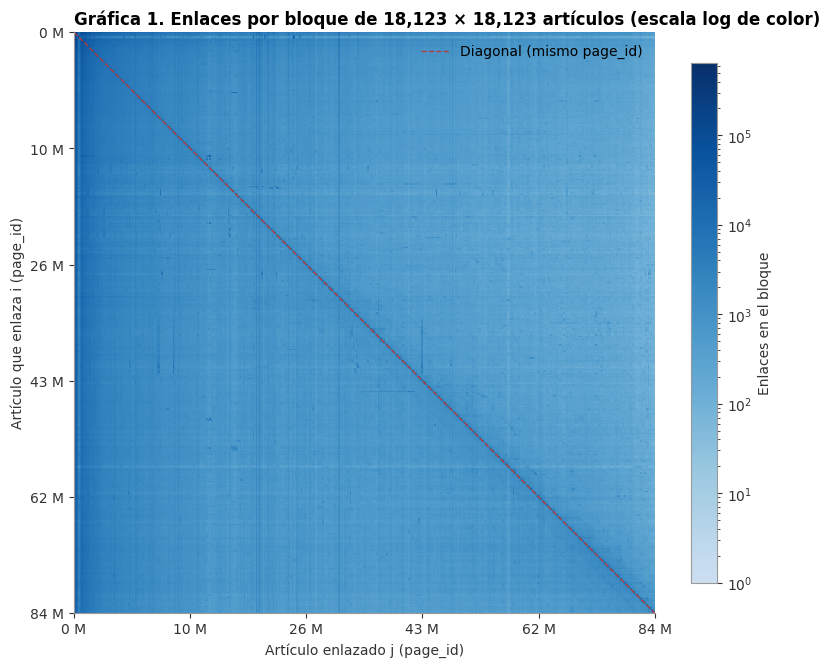

Enlaces hacia un page_id menor (debajo de la diagonal): 73.01 % | hacia uno mayor: 26.99 %


In [4]:
# Gráfica 1. Patrón de la matriz de adyacencia por bloques, con los nodos en orden de page_id
B = 400
tam_bloque = int(np.ceil(n / B))
conteo = np.bincount((origen // tam_bloque).astype(np.int64) * B + destino // tam_bloque, minlength=B * B).reshape(B, B)
conteo = conteo.astype(float)
conteo[conteo == 0] = np.nan

fig, ax = plt.subplots(figsize=(8.2, 7))
im = ax.imshow(conteo, cmap=CMAP_SEC, norm=LogNorm(vmin=1, vmax=np.nanmax(conteo)), interpolation="nearest",
               extent=(0, n, n, 0))
ax.plot([0, n], [0, n], color=ROJO, linewidth=1, linestyle="--", label="Diagonal (mismo page_id)")
marcas = np.linspace(0, n - 1, 6).astype(int)
ax.set_xticks(marcas, labels=[f"{ids[i] / 1e6:.0f} M" for i in marcas])
ax.set_yticks(marcas, labels=[f"{ids[i] / 1e6:.0f} M" for i in marcas])
estilo_ejes(ax, f"Gráfica 1. Enlaces por bloque de {tam_bloque:,} × {tam_bloque:,} artículos (escala log de color)",
            "Artículo enlazado j (page_id)", "Artículo que enlaza i (page_id)", rejilla=None)
fig.colorbar(im, ax=ax, label="Enlaces en el bloque", shrink=0.82)
ax.legend(loc="upper right")
plt.tight_layout()
archivo_g1 = reg.guardar_figura(fig, "grafica_01_patron_matriz", NB)
plt.show()

abajo = (destino < origen).mean()
print(f"Enlaces hacia un page_id menor (debajo de la diagonal): {pct(abajo)} | hacia uno mayor: {pct(1 - abajo)}")
del conteo

**Observaciones.** La matriz parece llena solo por la escala: cada cuadro junta 18,123 × 18,123 artículos. En realidad solo el 0.00045 % de las entradas vale 1, y por eso el formato disperso ocupa 2.86 GB, contra 420 TB que ocuparía la matriz completa.

La franja oscura de la izquierda son los `page_id` más bajos, que reciben enlaces de todas partes. El 73.01 % de los enlaces va hacia un `page_id` menor, es decir, hacia una página creada antes. Hacia el final, la zona junto a la diagonal se oscurece: probablemente son artículos creados en fechas cercanas que se enlazan entre sí, aunque aquí no lo medimos.

In [5]:
# Guardado de A en .npz con el mapeo índice → page_id, en el formato que lee scipy.sparse.load_npz
t0 = time.perf_counter()
np.savez_compressed(ARCHIVO_MATRIZ, data=A.data, indices=A.indices, indptr=A.indptr, format=np.bytes_("csr"),
                    shape=np.array(A.shape), ids=ids)
A_leida = sp.load_npz(ARCHIVO_MATRIZ)
assert A_leida.shape == A.shape and np.array_equal(A_leida.indptr, A.indptr) and np.array_equal(A_leida.indices, A.indices)
assert np.array_equal(np.load(ARCHIVO_MATRIZ)["ids"], ids)
print(f"{ARCHIVO_MATRIZ.name}: {tamano(ARCHIVO_MATRIZ.stat().st_size)} en {time.perf_counter() - t0:.0f} s | "
      f"matriz {A_leida.shape}, nnz = {A_leida.nnz:,}")
del A_leida, origen, destino
reg.registrar_paso("02.2", inicio, [reg.guardar_tabla(memoria, "02_memoria_matriz", NB), archivo_g1, ARCHIVO_MATRIZ],
                   f"nnz = {A.nnz:,}; {pct(abajo)} de los enlaces hacia un page_id menor")

adyacencia.npz: 720.2 MB en 82 s | matriz (7249099, 7249099), nnz = 236,242,098


<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · REPRESENTACIÓN</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">3. Matriz de transición y estructura de la red</span></div>

PageRank parte de un lector que está en un artículo y elige al azar uno de sus enlaces. Si el artículo $i$ tiene $k_{out}(i)$ enlaces de salida, cada uno se sigue con probabilidad $1 / k_{out}(i)$. Eso se escribe con la **matriz de transición**:

$$M_{ji} = \begin{cases} 1 / k_{out}(i) & \text{si } i \to j \\ 0 & \text{en otro caso} \end{cases}$$

Si $v$ dice en qué artículo puede estar el lector ahora, $Mv$ dice dónde puede estar después de dar un clic. Para no guardar otra matriz, calculamos ese producto con $A^\top$: dividimos $v$ entre los grados de salida y multiplicamos.

Hay dos problemas clásicos:

- **Colgantes:** artículos sin enlaces de salida. El lector no tiene a dónde ir y su probabilidad se pierde.
- **Trampas de araña:** grupos de artículos que solo se enlazan entre sí. El lector entra y no sale, y el grupo acumula toda la probabilidad.

También medimos la forma general de la red. El **núcleo** es el grupo más grande de artículos que pueden llegar unos a otros siguiendo enlaces. **IN** son los que llegan al núcleo, pero a los que no se llega desde él. **OUT** son los que se alcanzan desde el núcleo, pero no regresan a él.

In [6]:
# Producto por bloques de filas en paralelo y matriz Aᵀ dividida en bloques
inicio = time.time()
BLOQUES = 16
POOL = ThreadPoolExecutor(BLOQUES)


def partir(X, bloques=BLOQUES):
    """
    Divide una matriz CSR en bloques consecutivos de filas.

    Parámetros
    ----------
    X : scipy.sparse.csr_matrix
        Matriz a dividir.
    bloques : int
        Número de bloques.

    Retorna
    -------
    list of scipy.sparse.csr_matrix
        Bloques de filas, en orden.
    """
    cortes = np.linspace(0, X.shape[0], bloques + 1).astype(int)
    return [X[a:b] for a, b in zip(cortes[:-1], cortes[1:])]


def producto(bloques, x):
    """
    Calcula X @ x multiplicando en paralelo los bloques de filas de X.

    Parámetros
    ----------
    bloques : list of scipy.sparse.csr_matrix
        Bloques de filas de X (salida de `partir`).
    x : np.ndarray
        Vector (n,) o matriz densa (n, K).

    Retorna
    -------
    np.ndarray
        El producto, con las filas en el orden original.
    """
    return np.concatenate(list(POOL.map(lambda bloque: bloque @ x, bloques)))


AT_bloques = partir(A.T.tocsr())
x = np.random.default_rng(42).random(n)
t0 = time.perf_counter(); y_simple = A.T @ x; t_simple = time.perf_counter() - t0
t0 = time.perf_counter(); y_bloques = producto(AT_bloques, x); t_bloques = time.perf_counter() - t0
assert np.allclose(y_simple, y_bloques, rtol=1e-12, atol=0)
print(f"Aᵀx: {t_simple:.2f} s con un núcleo | {t_bloques:.2f} s con {BLOQUES} bloques en paralelo | mismo resultado")
del x, y_simple, y_bloques

Aᵀx: 1.28 s con un núcleo | 0.62 s con 16 bloques en paralelo | mismo resultado


In [7]:
# Columnas de M, nodos colgantes y fuga de probabilidad sin teletransportación
inv_k_out = np.divide(1.0, k_out, out=np.zeros(n), where=k_out > 0)
colgantes = k_out == 0
print(f"Columnas de M que suman 1: {(~colgantes).sum():,} | que suman 0 (colgantes): {colgantes.sum():,}")

v = np.full(n, 1 / n)
masa = [v.sum()]
for _ in range(30):
    v = producto(AT_bloques, v * inv_k_out)
    masa.append(v.sum())
print("Probabilidad total tras t pasos de v' = Mv, sin teletransportación:")
print(" | ".join(f"t = {t}: {masa[t]:.4f}" for t in [0, 1, 2, 5, 10, 20, 30]))
tabla_fuga = pd.DataFrame({"probabilidad total": masa}).rename_axis("t")

# Eliminación recursiva de colgantes: al quitar un colgante, quienes solo lo enlazaban a él se vuelven colgantes
vivo = np.ones(n, dtype=bool)
k_vivo = k_out.astype(np.int64)
rondas = []
while True:
    quitar = vivo & (k_vivo == 0)
    if not quitar.any():
        break
    vivo[quitar] = False
    rondas.append(int(quitar.sum()))
    k_vivo = k_vivo - np.rint(A @ quitar.astype(float)).astype(np.int64)
print(f"Eliminación recursiva de colgantes: {len(rondas)} rondas, se quitan {(~vivo).sum():,} nodos "
      f"({pct((~vivo).mean(), 3)}) | por ronda: {rondas}")
del v, k_vivo

Columnas de M que suman 1: 7,241,465 | que suman 0 (colgantes): 7,634


Probabilidad total tras t pasos de v' = Mv, sin teletransportación:
t = 0: 1.0000 | t = 1: 0.9989 | t = 2: 0.9981 | t = 5: 0.9977 | t = 10: 0.9972 | t = 20: 0.9962 | t = 30: 0.9952


Eliminación recursiva de colgantes: 2 rondas, se quitan 7,658 nodos (0.106 %) | por ronda: [7634, 24]


In [8]:
# SCC, trampas de araña y estructura de corbata (Broder et al., 2000)
t0 = time.perf_counter()
n_scc, scc = connected_components(A, directed=True, connection="strong")
segundos_scc = time.perf_counter() - t0
tam_scc = np.bincount(scc)
mayor = tam_scc.argmax()

# Una SCC tiene salida si alguna arista va de ella a otra SCC
filas = np.repeat(np.arange(n, dtype=np.int32), np.diff(A.indptr))
scc_origen, scc_destino = scc[filas], scc[A.indices]
tiene_salida = np.zeros(n_scc, dtype=bool)
tiene_salida[np.unique(scc_origen[scc_origen != scc_destino])] = True
del filas, scc_origen, scc_destino
sin_salida = ~tiene_salida
trampas = np.where(sin_salida & (tam_scc > 1))[0]

# IN: llegan a la SCC mayor; OUT: se alcanzan desde ella (BFS hacia adelante en A y hacia atrás en Aᵀ)
semilla = np.where(scc == mayor)[0][0]
alcanzables = np.zeros(n, dtype=bool)
alcanzables[breadth_first_order(A, semilla, directed=True, return_predecessors=False)] = True
llegan = np.zeros(n, dtype=bool)
llegan[breadth_first_order(A.T.tocsr(), semilla, directed=True, return_predecessors=False)] = True
en_scc = scc == mayor
corbata = pd.Series({
    "SCC mayor (núcleo)": en_scc.sum(),
    "IN (llegan al núcleo, no se alcanzan desde él)": (llegan & ~en_scc).sum(),
    "OUT (se alcanzan desde el núcleo, no llegan a él)": (alcanzables & ~en_scc).sum(),
    "Resto (tentáculos, tubos y desconectados)": (~llegan & ~alcanzables).sum(),
}, name="artículos").to_frame()
corbata["%"] = corbata["artículos"].map(lambda x: pct(x / n))
corbata["artículos"] = corbata["artículos"].map("{:,}".format)
print(f"SCC: {n_scc:,} componentes en {segundos_scc:.0f} s | sin salida: {sin_salida.sum():,} "
      f"(de un nodo = colgantes: {(sin_salida & (tam_scc == 1)).sum():,}; trampas de más de un nodo: {len(trampas)})")
display(corbata)

tabla_trampas = pd.DataFrame([{"trampa": t, "artículos": " ↔ ".join(nodos.loc[scc == t, "title"]),
                               "k_in de cada uno": nodos.loc[scc == t, "grado_entrada"].tolist()} for t in trampas])
print("Las trampas de araña:")
display(tabla_trampas.set_index("trampa"))
reg.registrar_paso("02.3", inicio, [
    reg.guardar_tabla(tabla_fuga, "03_fuga_probabilidad", NB),
    reg.guardar_tabla(pd.DataFrame({"colgantes quitados": rondas}).rename_axis("ronda"), "03_rondas_colgantes", NB),
    reg.guardar_tabla(corbata, "03_corbata", NB), reg.guardar_tabla(tabla_trampas, "03_trampas", NB),
], f"{colgantes.sum():,} colgantes; SCC mayor {pct(tam_scc.max() / n)}; {len(trampas)} trampas de araña")

SCC: 567,981 componentes en 7 s | sin salida: 7,642 (de un nodo = colgantes: 7,634; trampas de más de un nodo: 8)


,artículos,%
SCC mayor (núcleo),"6,654,680",91.80 %
"IN (llegan al núcleo, no se alcanzan desde él)","586,745",8.09 %
"OUT (se alcanzan desde el núcleo, no llegan a él)","4,691",0.06 %
"Resto (tentáculos, tubos y desconectados)","2,983",0.04 %


Las trampas de araña:


,artículos,k_in de cada uno
trampa,,
702,Physophora hydrostatica ↔ Physophora,"[4, 4]"
2456,Pierre Verdrager ↔ L'enfant interdit,"[2, 1]"
2636,Badr Lama ↔ The Beautiful Bedouin,"[4, 1]"
3490,Crozier (surname) ↔ Crosier (surname),"[4, 2]"
3588,World lexicon of Tolnai ↔ New world lexicon of Tolnai,"[4, 3]"
3897,Ashiyane ↔ Behrooz Kamalian,"[2, 2]"
4419,Shackel ↔ Shackell,"[3, 1]"
64988,Masnik ↔ Masnick,"[1, 1]"


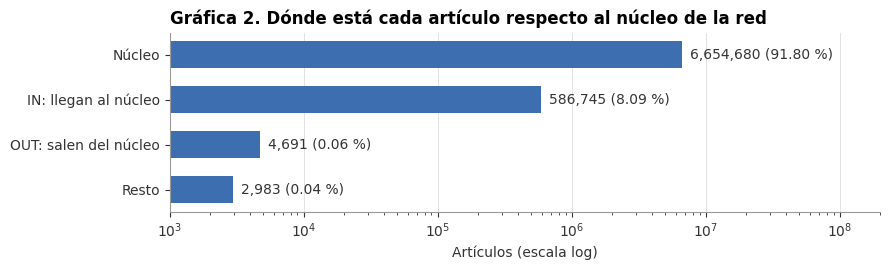

In [9]:
# Gráfica 2. Estructura de la red: núcleo, IN, OUT y resto
partes = pd.Series({"Núcleo": en_scc.sum(), "IN: llegan al núcleo": (llegan & ~en_scc).sum(),
                    "OUT: salen del núcleo": (alcanzables & ~en_scc).sum(),
                    "Resto": (~llegan & ~alcanzables).sum()})
fig, ax = plt.subplots(figsize=(9, 2.8))
ax.barh(partes.index[::-1], partes.to_numpy()[::-1], color=AZUL, height=0.6)
for y, valor in enumerate(partes.to_numpy()[::-1]):
    ax.text(valor * 1.15, y, f"{valor:,} ({pct(valor / n)})", va="center", color=TINTA)
ax.set_xscale("log")
ax.set_xlim(1e3, 2e8)
estilo_ejes(ax, "Gráfica 2. Dónde está cada artículo respecto al núcleo de la red", "Artículos (escala log)", rejilla="x")
plt.tight_layout()
reg.guardar_figura(fig, "grafica_02_estructura_red", NB)
plt.show()

**Observaciones.** El eje está en escala logarítmica para que se vean los grupos pequeños, así que conviene leer las cifras y no el largo de las barras.

El 91.80 % de los artículos está en el núcleo: desde cualquiera de ellos se puede llegar a cualquier otro siguiendo enlaces. Casi todo lo demás está en IN (8.09 %), que en buena parte son artículos a los que nadie enlaza. Hay 457,439 artículos sin enlaces de entrada.

Los dos problemas de PageRank existen, pero son pequeños. Hay 7,634 colgantes, y sin salto al azar el lector conserva 99.52 % de la probabilidad después de 30 pasos. Las 8 trampas de araña tienen dos artículos cada una, como *Masnik ↔ Masnick*. Aun así hay que tratarlos, porque sin ese ajuste la cuenta no suma 1 y el método no tiene garantía de converger.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · REPRESENTACIÓN</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">3.1 Grafo de análisis: sin páginas de desambiguación</span></div>

Quitamos las páginas de desambiguación con todas sus aristas. Una página como *Mercury* no trata de un tema: es un menú que enlaza a todo lo que se llama igual. Conectaría artículos que no tienen relación entre sí.

Las listas y las páginas de año sí se quedan, porque tienen contenido. Más adelante (sección 6.1) comprobamos que esta decisión casi no cambia el resultado.

Desde aquí, todo se calcula sobre este grafo de análisis.

In [10]:
# Grafo de análisis: subgrafo inducido por los artículos que no son de desambiguación
inicio = time.time()
conserva = ~nodos["is_disambig"].to_numpy()
de_desamb = int(A[~conserva].nnz)
a_desamb = int(k_in[~conserva].sum())

A_an = A[conserva][:, conserva].tocsr()
nodos_an = nodos[conserva].reset_index(drop=True)
nodos_an.index.name = "indice"
n_an = len(nodos_an)
k_out_an = np.asarray(A_an.sum(axis=1)).ravel()
k_in_an = np.asarray(A_an.sum(axis=0)).ravel()
nodos_an["k_out"], nodos_an["k_in"] = k_out_an, k_in_an
n_scc_an, scc_an = connected_components(A_an, directed=True, connection="strong")

comparacion_grafos = pd.DataFrame({
    "completo": [f"{n:,}", f"{A.nnz:,}", f"{(k_out == 0).sum():,}", pct(tam_scc.max() / n)],
    "análisis (sin desambiguación)": [f"{n_an:,}", f"{A_an.nnz:,}", f"{(k_out_an == 0).sum():,}",
                                       pct(np.bincount(scc_an).max() / n_an)],
}, index=["nodos", "aristas", "nodos colgantes", "SCC mayor (% de nodos)"])
display(comparacion_grafos)
print(f"Aristas quitadas: {A.nnz - A_an.nnz:,} | que salen de desambiguaciones: {de_desamb:,} | "
      f"que llegan a ellas: {a_desamb:,}")
print("Desambiguaciones con más enlaces de entrada (enlaces que deberían apuntar a un artículo concreto):")
top_desamb = nodos.loc[~conserva].nlargest(10, "grado_entrada")[["id", "title", "grado_entrada", "grado_salida"]]
display(top_desamb.head(5))

inv_k_out_an = np.divide(1.0, k_out_an, out=np.zeros(n_an), where=k_out_an > 0)
AT_an_bloques = partir(A_an.T.tocsr())
A_an_bloques = partir(A_an)
del A   # para la comprobación de la sección 6.1 basta con AT_bloques
reg.registrar_paso("02.3.1", inicio, [reg.guardar_tabla(comparacion_grafos, "03_1_comparacion_grafos", NB),
                                      reg.guardar_tabla(top_desamb.set_index("id"), "03_1_desambiguaciones_mas_enlazadas", NB)],
                   f"{n_an:,} nodos y {A_an.nnz:,} aristas")

,completo,análisis (sin desambiguación)
nodos,"7,249,099","6,879,374"
aristas,"236,242,098","233,221,445"
nodos colgantes,"7,634","7,557"
SCC mayor (% de nodos),91.80 %,94.70 %


Aristas quitadas: 3,020,653 | que salen de desambiguaciones: 2,907,694 | que llegan a ellas: 277,405
Desambiguaciones con más enlaces de entrada (enlaces que deberían apuntar a un artículo concreto):


,id,title,grado_entrada,grado_salida
indice,,,,
134315,290282,State,457,77
2232966,18573408,List of the oldest buildings in Massachusetts,143,216
11617,23813,Pope Stephen II,136,57
2943313,26181056,And,119,27
11031,22622,Orthodox,109,33


**Observaciones.** Quitar las 369,725 páginas de desambiguación elimina el 5.10 % de los nodos, pero solo el 1.28 % de las aristas. El núcleo sube de 91.80 % a 94.70 % de los artículos.

La tabla de arriba muestra un límite de la marca que viene del notebook 1: *List of the oldest buildings in Massachusetts* aparece como desambiguación, aunque parece una lista. Los enlaces que llegan a estas páginas son pocos (*State* recibe 457), y cada uno es un enlace que debería apuntar a un artículo concreto.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · PAGERANK</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">4. PageRank</span></div>

**La idea.** Un lector navega sin parar. En cada paso, con probabilidad $\beta$ sigue un enlace al azar, y con probabilidad $1 - \beta$ se aburre y salta a cualquier artículo. El PageRank de un artículo es la proporción del tiempo que el lector pasa en él a la larga.

**La fórmula.**

$$r = \beta M r + (1 - \beta)\,\frac{e}{n}$$

- $r$: el vector de puntajes. Sus valores suman 1.
- $M$: la matriz de transición de la sección 3.
- $\beta$: la probabilidad de seguir un enlace. Usamos $\beta = 0.85$, así que el lector da en promedio unos 5.7 clics antes de saltar.
- $e / n$: el salto a un artículo cualquiera, todos con la misma probabilidad.

Para un solo artículo $j$ se lee así:

$$r_j = \beta \sum_{i \to j} \frac{r_i}{k_{out}(i)} + \frac{1 - \beta}{n}$$

Cada artículo $i$ que enlaza a $j$ le pasa una parte de su puntaje, repartida entre todos sus enlaces. Por eso un enlace vale más si viene de un artículo importante y con pocos enlaces.

**Ejemplo.** Si $i$ tiene $r_i = 0.001$ y 10 enlaces, cada uno entrega $0.85 \times 0.001 / 10 = 0.000085$. Si tuviera 1,000 enlaces, cada uno entregaría 100 veces menos.

**Los colgantes.** La probabilidad que llega a un artículo sin salidas se reparte igual que el salto. Así la suma de $r$ siempre es 1. Las trampas de araña también dejan de ser un problema, porque el lector siempre puede saltar.

**Cómo se calcula.** Con el método de potencias: empezamos con todos los puntajes iguales y aplicamos la fórmula una y otra vez. Paramos cuando el cambio total es menor que $10^{-10}$:

$$\lVert r_{t+1} - r_t \rVert_1 < 10^{-10}$$

In [11]:
# PageRank por el método de potencias sobre la matriz dispersa
inicio = time.time()
TOL = 1e-10
BETAS = [0.70, 0.85, 0.95]


def pagerank_potencia(AT_bloques, inv_k_out, v=None, beta=0.85, tol=TOL, max_iter=1000):
    """
    Calcula PageRank por el método de potencias, con los colgantes repartidos según v.

    Parámetros
    ----------
    AT_bloques : list of scipy.sparse.csr_matrix
        Bloques de filas de Aᵀ (salida de `partir`).
    inv_k_out : np.ndarray
        1 / k_out para cada nodo; 0 en los colgantes.
    v : np.ndarray, opcional
        Vector de teletransportación (no negativo); se normaliza a suma 1. Si es None, uniforme.
    beta : float
        Probabilidad de seguir un enlace.
    tol : float
        Criterio de paro sobre ‖r_{t+1} − r_t‖₁.
    max_iter : int
        Número máximo de iteraciones.

    Retorna
    -------
    tuple of (np.ndarray, int)
        Vector de PageRank (suma 1) e iteraciones hasta converger. Si no converge, devuelve el último vector y
        max_iter, y anota el residuo final en RESUMEN.md.
    """
    n = len(inv_k_out)
    v = np.full(n, 1 / n) if v is None else v / v.sum()
    r = np.full(n, 1 / n)
    for iteracion in range(1, max_iter + 1):
        nuevo = beta * producto(AT_bloques, r * inv_k_out)
        nuevo += (1 - nuevo.sum()) * v
        error = np.abs(nuevo - r).sum()
        r = nuevo
        if error < tol:
            return r, iteracion
    reg.nota(f"PageRank (β = {beta}) no convergió en {max_iter} iteraciones; residuo final ‖r_t+1 − r_t‖₁ = {error:.2e}")
    return r, max_iter


pr, filas_pr = {}, []
for beta in BETAS:
    t0 = time.perf_counter()
    pr[beta], iteraciones = pagerank_potencia(AT_an_bloques, inv_k_out_an, beta=beta)
    segundos = time.perf_counter() - t0
    filas_pr.append({"β": beta, "iteraciones": iteraciones, "segundos": round(segundos), "suma": round(pr[beta].sum(), 10),
                     "máximo": pr[beta].max(), "mínimo": pr[beta].min(),
                     "máximo / mínimo": round(pr[beta].max() / pr[beta].min()),
                     "top 1": nodos_an.loc[pr[beta].argmax(), "title"]})
display(pd.DataFrame(filas_pr).set_index("β"))
pr85 = pr[0.85]

,iteraciones,segundos,suma,máximo,mínimo,máximo / mínimo,top 1
β,,,,,,,
0.70,42,28,1.0,0.000853,4.366709e-08,19525,Association football
0.85,70,47,1.0,0.000934,2.184883e-08,42769,United States
0.95,163,109,1.0,0.001037,7.294736e-09,142222,United States


**Comprobación.** Revisamos dos cosas. Primero, que al aplicar la fórmula una vez más el vector casi no cambie. Segundo, que en un grafo de 20,000 artículos nuestro código dé lo mismo que `nx.pagerank`.

In [12]:
# Validación: residuo del punto fijo y comparación con networkx en un subgrafo
siguiente = 0.85 * producto(AT_an_bloques, pr85 * inv_k_out_an)
siguiente += (1 - siguiente.sum()) / n_an
residuo = np.abs(siguiente - pr85).sum()
del siguiente

SUB = np.sort(np.argsort(-k_in_an)[:20_000])
A_sub = A_an[SUB][:, SUB].tocsr()
k_sub = np.asarray(A_sub.sum(axis=1)).ravel()
inv_sub = np.divide(1.0, k_sub, out=np.zeros(len(SUB)), where=k_sub > 0)
pr_sub, _ = pagerank_potencia(partir(A_sub.T.tocsr(), 1), inv_sub, beta=0.85, tol=1e-13)
pr_nx = nx.pagerank(nx.from_scipy_sparse_array(A_sub, create_using=nx.DiGraph), alpha=0.85, tol=1e-14, max_iter=10_000)
pr_nx = np.array([pr_nx[i] for i in range(len(SUB))])
diferencia = np.abs(pr_sub - pr_nx).max()
tabla_validacion = pd.Series({"residuo del punto fijo (grafo de análisis)": residuo, "nodos del subgrafo": len(SUB),
                              "aristas del subgrafo": A_sub.nnz, "diferencia máxima con nx.pagerank": diferencia},
                             name="valor").to_frame()
if residuo > 1e-9 or diferencia > 1e-9:
    reg.nota(f"Validación de PageRank fuera de tolerancia: residuo {residuo:.2e}, diferencia con networkx {diferencia:.2e}")

print(f"Residuo del punto fijo ‖r − (βMr + …)‖₁ en el grafo de análisis: {residuo:.2e}")
print(f"Subgrafo de {len(SUB):,} nodos y {A_sub.nnz:,} aristas: diferencia máxima con nx.pagerank = {diferencia:.2e} "
      f"(PageRank máximo del subgrafo {pr_sub.max():.2e})")

Residuo del punto fijo ‖r − (βMr + …)‖₁ en el grafo de análisis: 6.51e-11
Subgrafo de 20,000 nodos y 1,527,547 aristas: diferencia máxima con nx.pagerank = 6.73e-13 (PageRank máximo del subgrafo 3.06e-03)


In [13]:
# Top 20 de PageRank con β = 0.85, junto a su lugar por número de enlaces recibidos
lugar_kin = pd.Series(k_in_an).rank(ascending=False, method="min").astype(int).to_numpy()


def tabla_top(puntaje, k=20, nombre="PageRank"):
    """
    Arma la tabla de los k artículos con mayor puntaje, con sus grados y su lugar por grado de entrada.

    Parámetros
    ----------
    puntaje : np.ndarray
        Puntaje por índice de nodo del grafo de análisis.
    k : int
        Número de artículos.
    nombre : str
        Nombre de la columna del puntaje.

    Retorna
    -------
    pd.DataFrame
        Título, grados, marcas, puntaje y lugar por k_in.
    """
    top = np.argsort(-puntaje)[:k]
    return pd.DataFrame({
        "artículo": nodos_an.loc[top, "title"].to_numpy(), "k_in": k_in_an[top], "k_out": k_out_an[top],
        "lista / cronología": np.where(nodos_an.loc[top, "es_lista"], "lista",
                                       np.where(nodos_an.loc[top, "es_cronologia"], "cronología", "")),
        nombre: puntaje[top], "lugar por k_in": lugar_kin[top],
    }, index=pd.RangeIndex(1, k + 1, name="lugar"))


top20_pr = tabla_top(pr85)
display(top20_pr.style.format({"PageRank": "{:.3e}", "k_in": "{:,}", "k_out": "{:,}", "lugar por k_in": "{:,}"}))
vectores_pr = pd.DataFrame({"id": nodos_an["id"], "title": nodos_an["title"]} |
                           {f"pagerank_{beta:.2f}": pr[beta] for beta in BETAS})
reg.registrar_paso("02.4", inicio, [
    reg.guardar_parquet(vectores_pr, "04_pagerank", NB),
    reg.guardar_tabla(pd.DataFrame(filas_pr).set_index("β"), "04_pagerank_por_beta", NB),
    reg.guardar_tabla(tabla_validacion, "04_validacion", NB), reg.guardar_tabla(top20_pr, "04_top20_pagerank", NB),
], " | ".join(f"β = {f['β']}: {f['iteraciones']} it" for f in filas_pr) + f" | dif. con networkx {diferencia:.1e}")

,artículo,k_in,k_out,lista / cronología,PageRank,lugar por k_in
lugar,,,,,,
1,United States,"218,342.0","1,602.0",,9.345e-04,3
2,The New York Times,"203,648.0",611.0,,8.835e-04,4
3,World War II,"221,247.0",956.0,,8.505e-04,2
4,Association football,"264,742.0",332.0,,7.402e-04,1
5,France,"141,560.0","1,194.0",,5.967e-04,6
6,United Kingdom,"101,389.0","1,405.0",,5.370e-04,13
7,New York City,"149,389.0","1,321.0",,5.254e-04,5
8,The Guardian,"112,739.0",636.0,,4.773e-04,10
9,Germany,"107,148.0",943.0,,4.765e-04,11


**Observaciones.** El resultado es confiable: al aplicar la fórmula otra vez, el vector cambia 6.51e-11, y en el grafo de 20,000 artículos la diferencia con `nx.pagerank` es de 6.73e-13.

Arriba quedan países, ciudades, guerras y medios: *United States*, *The New York Times*, *World War II*. No son necesariamente los artículos más leídos, porque aquí no hay visitas. Son aquellos a los que más se llega siguiendo enlaces.

Ninguna lista ni cronología entra al top-20. Algunos casos llaman la atención. *Association football* es el más enlazado (264,742 enlaces), pero queda en cuarto lugar. *Oxford University Press* sube del lugar 109 por enlaces al 17, y *Latin* del 143 al 20. *Moth* (lugar 18) probablemente se debe a los muchos artículos de especies, aunque aquí no lo comprobamos.

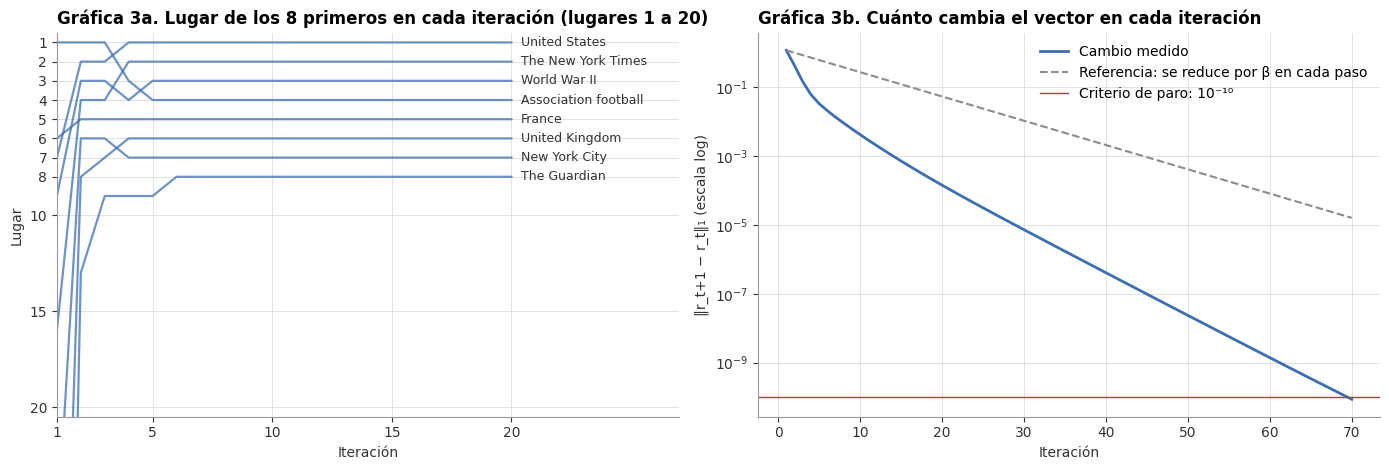

Lugares en las iteraciones 1, 2, 3, 5, 10 y 30:


title,United States,The New York Times,World War II,Association football,France,United Kingdom,New York City,The Guardian
iteración,,,,,,,,
1,7,16,9,1,6,46,27,71
2,2,4,3,1,5,8,6,13
3,2,4,3,1,5,7,6,9
5,1,2,3,4,5,6,7,9
10,1,2,3,4,5,6,7,8
30,1,2,3,4,5,6,7,8


Primera iteración con cambio menor que 10⁻³: 15


In [14]:
# Gráfica 3. Cómo se acomodan los primeros lugares en cada iteración
seguidos = np.argsort(-pr85)[:8]
r_t = np.full(n_an, 1 / n_an)
lugares, cambios = [], []
for t in range(1, filas_pr[1]["iteraciones"] + 1):
    nuevo = 0.85 * producto(AT_an_bloques, r_t * inv_k_out_an)
    nuevo += (1 - nuevo.sum()) / n_an
    cambios.append(np.abs(nuevo - r_t).sum())
    r_t = nuevo
    if t <= 30:
        lugares.append([(r_t > r_t[i]).sum() + 1 for i in seguidos])
lugares = np.array(lugares)
del r_t, nuevo

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))
for columna, i in enumerate(seguidos):
    ax1.plot(range(1, 21), lugares[:20, columna], color=AZUL, linewidth=1.6, alpha=0.75)
    ax1.text(20.4, lugares[-1, columna], nodos_an.loc[i, "title"], va="center", fontsize=9, color=TINTA)
ax1.set_ylim(20.5, 0.5)
ax1.set_yticks([1, 2, 3, 4, 5, 6, 7, 8, 10, 15, 20])
ax1.set_xlim(1, 27)
ax1.set_xticks([1, 5, 10, 15, 20])
estilo_ejes(ax1, "Gráfica 3a. Lugar de los 8 primeros en cada iteración (lugares 1 a 20)", "Iteración", "Lugar", rejilla="both")
iteraciones_t = np.arange(1, len(cambios) + 1)
ax2.plot(iteraciones_t, cambios, color=AZUL, linewidth=2, label="Cambio medido")
ax2.plot(iteraciones_t, cambios[0] * 0.85 ** (iteraciones_t - 1), color=GRIS, linestyle="--", label="Referencia: se reduce por β en cada paso")
ax2.axhline(1e-10, color=ROJO, linewidth=1, label="Criterio de paro: 10⁻¹⁰")
ax2.set_yscale("log")
estilo_ejes(ax2, "Gráfica 3b. Cuánto cambia el vector en cada iteración", "Iteración", "‖r_t+1 − r_t‖₁ (escala log)", rejilla="both")
ax2.legend(loc="upper right")
plt.tight_layout()
reg.guardar_figura(fig, "grafica_03_iteraciones_pagerank", NB)
plt.show()
print("Lugares en las iteraciones 1, 2, 3, 5, 10 y 30:")
display(pd.DataFrame(lugares[[0, 1, 2, 4, 9, 29]], index=[1, 2, 3, 5, 10, 30], columns=nodos_an.loc[seguidos, "title"]).rename_axis("iteración"))
print("Primera iteración con cambio menor que 10⁻³:", next(t for t, x in enumerate(cambios, 1) if x < 1e-3))

**Observaciones.** En 3a, la primera iteración todavía se parece poco al resultado final: *Association football* va primero, *United States* séptimo y *The Guardian* en el lugar 71 (fuera de la gráfica). Para la iteración 5 ya están fijos los primeros 7 lugares, y para la 10 los 8 que seguimos.

En 3b, el cambio cae en línea recta en escala logarítmica. Baja de 10⁻³ en la iteración 15 y llega a 10⁻¹⁰ en la 70. La línea punteada es lo que se reduciría solo por $\beta$, y el cambio real va más rápido que ella.

Las dos gráficas dicen algo práctico: los primeros lugares se acomodan mucho antes de que el vector converja. Las 60 iteraciones restantes sirven para ordenar bien el resto de los 6.88 millones de artículos.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · PAGERANK</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">4.1 ¿Cuánto importa el valor de β?</span></div>

Comparamos los resultados con $\beta$ = 0.70, 0.85 y 0.95 con dos medidas:

- **Jaccard del top-k:** qué tanto coinciden los $k$ primeros de dos rankings. Vale 1 si son iguales y 0 si no comparten ninguno.

$$J = \frac{|T_a \cap T_b|}{|T_a \cup T_b|}$$

- **Spearman $\rho$:** qué tan parecido es el orden de todos los artículos. Vale 1 si el orden es idéntico.

,Jaccard top-20,Jaccard top-100,"Jaccard top-1,000",Spearman ρ
par de β,,,,
0.70 vs 0.85,0.667,0.724,0.807,0.9913
0.85 vs 0.95,0.818,0.681,0.778,0.9887
0.70 vs 0.95,0.600,0.481,0.625,0.9621


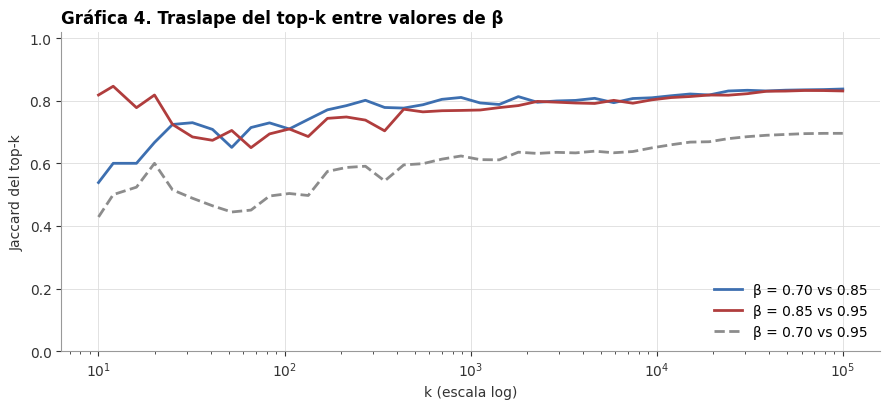

In [15]:
# Jaccard del top-k y correlación de Spearman entre pares de β
inicio = time.time()
def jaccard_top(a, b, k):
    """
    Índice de Jaccard entre los k nodos con mayor puntaje de dos rankings.

    Parámetros
    ----------
    a, b : np.ndarray
        Puntajes por índice de nodo.
    k : int
        Tamaño del top.

    Retorna
    -------
    float
        |top_a ∩ top_b| / |top_a ∪ top_b|.
    """
    ta, tb = np.argpartition(-a, k)[:k], np.argpartition(-b, k)[:k]
    comun = len(np.intersect1d(ta, tb))
    return comun / (2 * k - comun)


pares = [(0.70, 0.85), (0.85, 0.95), (0.70, 0.95)]
sensibilidad = pd.DataFrame([{
    "par de β": f"{a:.2f} vs {b:.2f}",
    "Jaccard top-20": round(jaccard_top(pr[a], pr[b], 20), 3),
    "Jaccard top-100": round(jaccard_top(pr[a], pr[b], 100), 3),
    "Jaccard top-1,000": round(jaccard_top(pr[a], pr[b], 1000), 3),
    "Spearman ρ": round(spearmanr(pr[a], pr[b]).statistic, 4),
} for a, b in pares]).set_index("par de β")
display(sensibilidad)

# Gráfica 4. Traslape del top-k en función de k
ks = np.unique(np.logspace(1, 5, 40).astype(int))
fig, ax = plt.subplots(figsize=(9, 4.2))
for (a, b), color, estilo in zip(pares, [AZUL, ROJO, GRIS], ["-", "-", "--"]):
    ax.plot(ks, [jaccard_top(pr[a], pr[b], k) for k in ks], color=color, linestyle=estilo, linewidth=2,
            label=f"β = {a:.2f} vs {b:.2f}")
ax.set_xscale("log")
ax.set_ylim(0, 1.02)
estilo_ejes(ax, "Gráfica 4. Traslape del top-k entre valores de β", "k (escala log)", "Jaccard del top-k", rejilla="both")
ax.legend(loc="lower right")
plt.tight_layout()
reg.registrar_paso("02.4.1", inicio, [reg.guardar_tabla(sensibilidad, "04_1_sensibilidad_beta", NB),
                                      reg.guardar_figura(fig, "grafica_04_jaccard_beta", NB)])
plt.show()

**Observaciones.** El orden general casi no cambia con $\beta$: Spearman vale 0.99 entre valores vecinos y 0.96 entre los extremos. Los primeros lugares sí cambian: entre 0.70 y 0.95, el top-100 comparte 65 artículos (Jaccard 0.48). Con 0.70 el primero es *Association football*, y con 0.85 y 0.95 es *United States*.

Las curvas suben con $k$, así que la diferencia está sobre todo en la parte alta de la lista. Si se reportan pocos artículos, el valor de $\beta$ importa. Un $\beta$ alto también cuesta más: 42 iteraciones con 0.70, 70 con 0.85 y 163 con 0.95.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · PAGERANK</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">4.2 ¿PageRank es solo contar enlaces?</span></div>

Si lo fuera, su ranking sería igual al de los enlaces recibidos $k_{in}$. La fórmula dice que no: cada enlace vale según quién lo da. Aquí vemos cuánto se parecen y qué artículos cambian más.

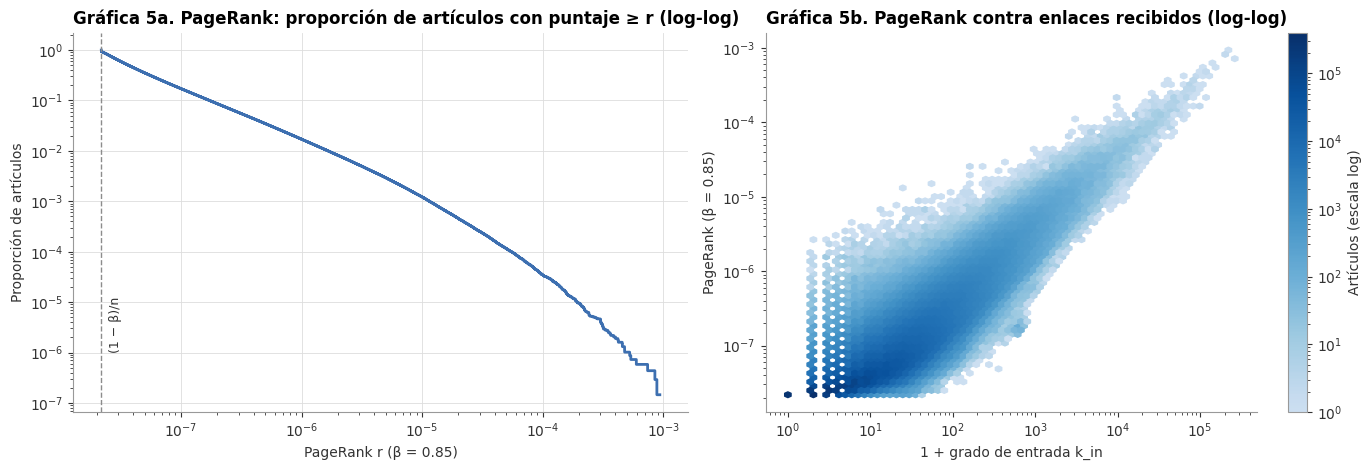

PageRank mínimo: 2.185e-08 | (1 − β)/n = 2.180e-08 | artículos con k_in = 0: 281,500


Spearman ρ(PageRank, k_in) = 0.8622 | Jaccard top-100 PageRank vs k_in = 0.600 | top-20: 0.538


In [16]:
# Gráfica 5. Distribución de PageRank (log-log) y PageRank contra grado de entrada
inicio = time.time()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))
ordenado = np.sort(pr85)[::-1]
rangos = np.unique(np.logspace(0, np.log10(n_an), 2000).astype(int)) - 1
ax1.step(ordenado[rangos], (rangos + 1) / n_an, where="post", color=AZUL, linewidth=2)
ax1.axvline((1 - 0.85) / n_an, color=GRIS, linestyle="--", linewidth=1)
ax1.text((1 - 0.85) / n_an * 1.15, 1e-6, "(1 − β)/n", fontsize=9, color=TINTA, rotation=90, va="bottom")
ax1.set_xscale("log")
ax1.set_yscale("log")
estilo_ejes(ax1, "Gráfica 5a. PageRank: proporción de artículos con puntaje ≥ r (log-log)", "PageRank r (β = 0.85)",
            "Proporción de artículos", rejilla="both")

hb = ax2.hexbin(k_in_an + 1, pr85, xscale="log", yscale="log", gridsize=70, bins="log", cmap=CMAP_SEC, mincnt=1)
fig.colorbar(hb, ax=ax2, label="Artículos (escala log)")
estilo_ejes(ax2, "Gráfica 5b. PageRank contra enlaces recibidos (log-log)", "1 + grado de entrada k_in",
            "PageRank (β = 0.85)", rejilla=None)
plt.tight_layout()
archivo_g3 = reg.guardar_figura(fig, "grafica_05_pagerank_vs_kin", NB)
plt.show()

rho_kin = spearmanr(pr85, k_in_an).statistic
print(f"PageRank mínimo: {pr85.min():.3e} | (1 − β)/n = {(1 - 0.85) / n_an:.3e} | "
      f"artículos con k_in = 0: {(k_in_an == 0).sum():,}")
print(f"Spearman ρ(PageRank, k_in) = {rho_kin:.4f} | Jaccard top-100 PageRank vs k_in = "
      f"{jaccard_top(pr85, k_in_an.astype(float), 100):.3f} | top-20: {jaccard_top(pr85, k_in_an.astype(float), 20):.3f}")

**Observaciones.** En 5a, pocos artículos concentran el puntaje: el mayor vale 42,769 veces más que el menor. Nadie baja de $(1 - \beta)/n = 2.18 \times 10^{-8}$, que es lo que recibe cualquier artículo por el salto al azar. Ese es el caso de los 281,500 artículos sin enlaces de entrada, que quedan cerca de ese piso.

En 5b se ve que PageRank y número de enlaces van juntos (Spearman 0.86), pero no son lo mismo. Alrededor de 1,000 enlaces recibidos, el PageRank varía cerca de 100 veces entre artículos. Los dos top-100 comparten 75 artículos (Jaccard 0.60), así que PageRank no es solo contar enlaces.

In [17]:
# Artículos con mayor diferencia entre su lugar en PageRank y su lugar por enlaces recibidos
lugar_pr = pd.Series(pr85).rank(ascending=False, method="min").astype(int).to_numpy()
comparacion = pd.DataFrame({"artículo": nodos_an["title"], "k_in": k_in_an, "k_out": k_out_an,
                            "lugar PageRank": lugar_pr, "lugar k_in": lugar_kin})
comparacion["suben (lugares)"] = comparacion["lugar k_in"] - comparacion["lugar PageRank"]
top500 = comparacion[comparacion["lugar PageRank"] <= 500]
print("Dentro del top-500 de PageRank, los que más suben respecto a su lugar por k_in:")
suben = top500.nlargest(8, "suben (lugares)")
bajan = comparacion[comparacion["lugar k_in"] <= 500].nsmallest(8, "suben (lugares)")
display(suben)
print("Dentro del top-500 por k_in, los que más bajan en PageRank:")
display(bajan)

# Calidad de quien enlaza: PageRank y k_out medianos de los que enlazan al que más sube y al que más baja
for etiqueta, fila in [("sube", top500["suben (lugares)"].idxmax()),
                       ("baja", comparacion.loc[comparacion["lugar k_in"] <= 500, "suben (lugares)"].idxmin())]:
    enlazan = A_an[:, fila].nonzero()[0]
    print(f"{etiqueta}: {nodos_an.loc[fila, 'title']} | lo enlazan: {len(enlazan):,} | PageRank mediano de quienes lo "
          f"enlazan: {np.median(pr85[enlazan]):.2e} | k_out mediano de quienes lo enlazan: {np.median(k_out_an[enlazan]):.0f}")
print(f"Referencia: PageRank mediano de todo el grafo {np.median(pr85):.2e} | k_out mediano {np.median(k_out_an):.0f}")
reg.registrar_paso("02.4.2", inicio, [archivo_g3, reg.guardar_tabla(suben, "04_2_suben_vs_kin", NB),
                                      reg.guardar_tabla(bajan, "04_2_bajan_vs_kin", NB)],
                   f"Spearman ρ(PageRank, k_in) = {rho_kin:.4f}")

Dentro del top-500 de PageRank, los que más suben respecto a su lugar por k_in:


,artículo,k_in,k_out,lugar PageRank,lugar k_in,suben (lugares)
indice,,,,,,
151909,Open access,2626.0,246.0,436,6677,6241
31611,Broadsheet,2909.0,36.0,220,5804,5584
10268,Oxford English Dictionary,3655.0,193.0,341,4206,3865
1660182,Web of Science,4233.0,71.0,449,3453,3004
12203,Social science,4454.0,411.0,467,3246,2779
1303777,Journal Citation Reports,4489.0,19.0,428,3200,2772
302957,Impact factor,4774.0,77.0,317,2925,2608
9501,Magazine,4874.0,211.0,376,2835,2459


Dentro del top-500 por k_in, los que más bajan en PageRank:


,artículo,k_in,k_out,lugar PageRank,lugar k_in,suben (lugares)
indice,,,,,,
231927,Season (sports),16935.0,242.0,2772,478,-2294
1932159,Review aggregator,16129.0,22.0,2468,497,-1971
610263,Oricon,17814.0,69.0,2171,440,-1731
3881,Drum kit,19384.0,233.0,2099,387,-1712
647251,ARIA Charts,23006.0,154.0,1902,312,-1590
837837,The A.V. Club,18820.0,52.0,1958,405,-1553
575334,Contemporary R&B,16509.0,217.0,1965,491,-1474
1526,Bass guitar,20256.0,107.0,1782,370,-1412


sube: Open access | lo enlazan: 2,626 | PageRank mediano de quienes lo enlazan: 1.21e-07 | k_out mediano de quienes lo enlazan: 22


baja: Season (sports) | lo enlazan: 16,935 | PageRank mediano de quienes lo enlazan: 4.57e-08 | k_out mediano de quienes lo enlazan: 55
Referencia: PageRank mediano de todo el grafo 3.68e-08 | k_out mediano 18


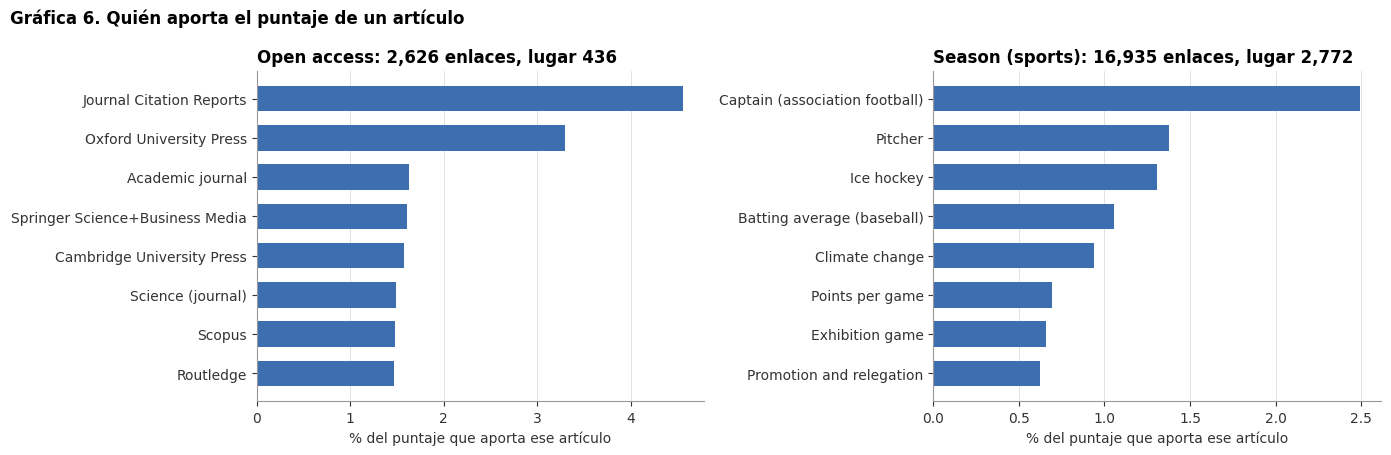

,enlaces recibidos,lugar por enlaces,lugar PageRank,PageRank,valor medio por enlace,% del puntaje de los 8 mayores
artículo,,,,,,
Open access,"2,626","6,677",436,7.17e-05,2.73e-08,17.1
Season (sports),"16,935",478,"2,772",2.19e-05,1.29e-09,9.1


WindowsPath('C:/Users/PC/Documents/IIMAS/Datos Masivos II/Práctica 3/T3_DMII/Wikipedia/data/resultados/02_pagerank_hits/04_2_aportes.csv')

In [18]:
# Gráfica 6. De dónde viene el puntaje: lo que aporta cada artículo que enlaza
j_sube = top500["suben (lugares)"].idxmax()
j_baja = comparacion.loc[comparacion["lugar k_in"] <= 500, "suben (lugares)"].idxmin()
filas_aporte = []
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, j in zip(ejes, [j_sube, j_baja]):
    enlazan = A_an[:, j].nonzero()[0]
    aporte = 0.85 * pr85[enlazan] * inv_k_out_an[enlazan]
    mejores = np.argsort(-aporte)[:8]
    titulos = nodos_an.loc[enlazan[mejores], "title"].to_numpy()
    ax.barh([t[:38] for t in titulos[::-1]], 100 * aporte[mejores][::-1] / pr85[j], color=AZUL, height=0.65)
    estilo_ejes(ax, f"{nodos_an.loc[j, 'title']}: {len(enlazan):,} enlaces, lugar {lugar_pr[j]:,}",
                "% del puntaje que aporta ese artículo", rejilla="x")
    filas_aporte.append({"artículo": nodos_an.loc[j, "title"], "enlaces recibidos": len(enlazan), "lugar por enlaces": lugar_kin[j],
                         "lugar PageRank": lugar_pr[j], "PageRank": pr85[j], "valor medio por enlace": aporte.mean(),
                         "% del puntaje de los 8 mayores": 100 * aporte[mejores].sum() / pr85[j]})
fig.suptitle("Gráfica 6. Quién aporta el puntaje de un artículo", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
reg.guardar_figura(fig, "grafica_06_aportes_pagerank", NB)
plt.show()
tabla_aporte = pd.DataFrame(filas_aporte).set_index("artículo")
display(tabla_aporte.style.format({"enlaces recibidos": "{:,}", "lugar por enlaces": "{:,}", "lugar PageRank": "{:,}", "PageRank": "{:.2e}",
                                   "valor medio por enlace": "{:.2e}", "% del puntaje de los 8 mayores": "{:.1f}"}))
reg.guardar_tabla(tabla_aporte, "04_2_aportes", NB)

**Observaciones.** *Season (sports)* tiene 6.4 veces más enlaces que *Open access* y aun así queda 2,336 lugares abajo. En promedio, cada enlace a *Open access* aporta 21 veces más.

La gráfica muestra por qué. A *Open access* lo enlazan páginas fuertes y con pocos enlaces, como *Journal Citation Reports* y *Oxford University Press*. El artículo típico que lo enlaza tiene 22 enlaces de salida, y el que enlaza a *Season (sports)* tiene 55. Además, el PageRank mediano de quienes lo enlazan es 2.6 veces mayor. Es justo lo que dice la fórmula: el enlace vale según quién lo da y entre cuántos reparte.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · PAGERANK</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">4.3 ¿Por qué aparecen medios y editoriales?</span></div>

En el top de PageRank hay periódicos y editoriales. Una razón posible: las referencias de Wikipedia suelen enlazar a la publicación, como en `|work=[[The New York Times]]`. Quien cita al periódico no está hablando de él.

Para medirlo leemos una muestra de 600 bloques del dump. En cada artículo comparamos los enlaces del texto completo con los que quedan al quitar las referencias (`<ref>…</ref>`), las plantillas de cita y los campos de fuente (`work`, `publisher`, `journal`…). Un enlace "solo en referencias" es el que desaparece al quitarlas.

La detección usa expresiones regulares, así que es aproximada, y solo cubre esta muestra. No cambiamos el grafo: es una medición para interpretar el resultado.

Muestra: 15,908 artículos y 563,749 enlaces | solo en referencias: 3.8 %


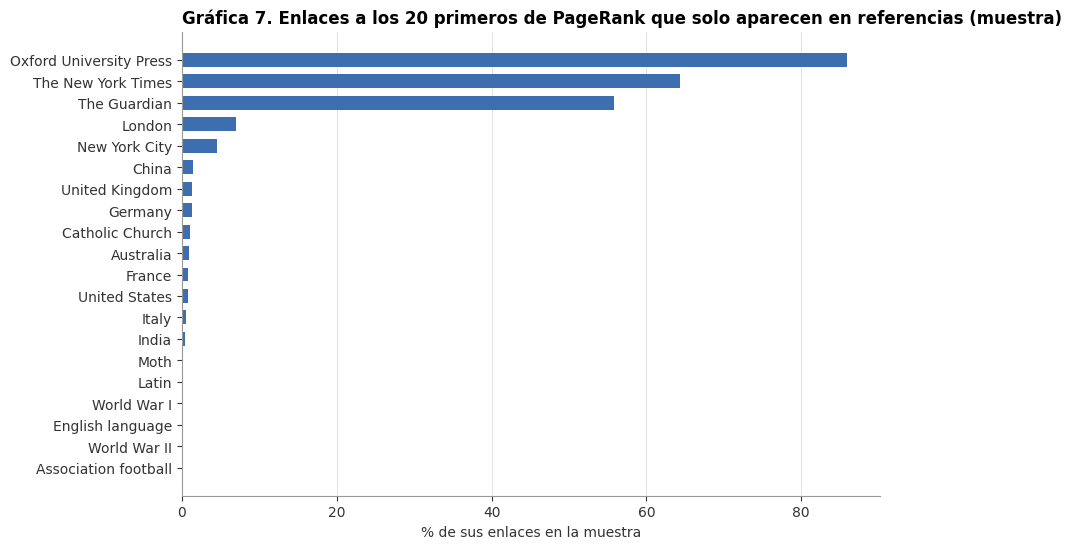

,enlaces en la muestra,solo en referencias,% solo en referencias
artículo,,,
Oxford University Press,92,79,86
The New York Times,407,262,64
The Guardian,242,135,56
London,299,21,7
New York City,307,14,5
China,205,3,1
United Kingdom,228,3,1
Germany,238,3,1
Catholic Church,100,1,1


In [19]:
# Enlaces que solo aparecen en referencias, en una muestra del dump; si no está el dump, se usa la tabla guardada
import xml.etree.ElementTree as ET
RUTA_XML = Path("..") / "data" / "enwiki-latest-pages-articles-multistream.xml.bz2"
RUTA_IDX = Path("..") / "data" / "enwiki-latest-pages-articles-multistream-index.txt.bz2"
ARCHIVO_REF = reg.carpeta(NB) / "04_3_enlaces_en_referencias.csv"
destinos = list(nodos_an.loc[np.argsort(-pr85)[:20], "title"])

if RUTA_XML.exists():
    from collections import Counter
    import wiki_extract as we
    RE_REF = re.compile(r"<ref\b[^>/]*>.*?</ref>", re.S | re.I)
    RE_CITA = re.compile(r"\{\{\s*(?:cite|citation)\b[^{}]*\}\}", re.S | re.I)
    RE_CAMPO = re.compile(r"\|\s*(?:work|publisher|journal|newspaper|website|magazine|periodical|agency|via|location|"
                          r"author-link\d*|authorlink\d*)\s*=\s*\[\[[^\]]*\]\]", re.I)
    offsets, _, _ = we.leer_indice(RUTA_IDX)
    muestra = np.random.default_rng(42).choice(offsets[1:-1], 600, replace=False)
    total, solo_ref = Counter(), Counter()
    articulos = enlaces_total = enlaces_solo = 0
    for offset in muestra:
        for pagina in we.paginas_de_texto(we.leer_stream(RUTA_XML, int(offset))):
            p = ET.fromstring(pagina)
            if p.findtext("ns") != "0" or p.find("redirect") is not None:
                continue
            nodo_texto = p.find("revision/text")
            texto = (nodo_texto.text or "") if nodo_texto is not None else ""
            if we.RE_DESAMBIG.search(texto):
                continue
            titulo = p.findtext("title")
            todos, _ = we.extraer_enlaces(texto, titulo)
            cuerpo, _ = we.extraer_enlaces(RE_CAMPO.sub(" ", RE_CITA.sub(" ", RE_REF.sub(" ", texto))), titulo)
            articulos += 1
            enlaces_total += len(todos)
            enlaces_solo += len(todos - cuerpo)
            total.update(todos)
            solo_ref.update(todos - cuerpo)
    tabla_ref = pd.DataFrame({"enlaces en la muestra": [total[d] for d in destinos],
                              "solo en referencias": [solo_ref[d] for d in destinos]}, index=pd.Index(destinos, name="artículo"))
    tabla_ref["% solo en referencias"] = 100 * tabla_ref["solo en referencias"] / tabla_ref["enlaces en la muestra"].clip(lower=1)
    tabla_ref.to_csv(ARCHIVO_REF, encoding="utf-8")
    pd.Series({"artículos en la muestra": articulos, "enlaces": enlaces_total, "enlaces solo en referencias": enlaces_solo,
               "% solo en referencias": 100 * enlaces_solo / enlaces_total}, name="valor").to_csv(
        reg.carpeta(NB) / "04_3_resumen_muestra.csv", encoding="utf-8")
else:
    tabla_ref = pd.read_csv(ARCHIVO_REF, index_col=0)
resumen_ref = pd.read_csv(reg.carpeta(NB) / "04_3_resumen_muestra.csv", index_col=0)["valor"]
print(f"Muestra: {resumen_ref['artículos en la muestra']:,.0f} artículos y {resumen_ref['enlaces']:,.0f} enlaces | "
      f"solo en referencias: {resumen_ref['% solo en referencias']:.1f} %")

# Gráfica 7. Parte de los enlaces de los 20 primeros de PageRank que solo está en referencias
orden_ref = tabla_ref.sort_values("% solo en referencias")
fig, ax = plt.subplots(figsize=(9, 5.6))
ax.barh(orden_ref.index, orden_ref["% solo en referencias"], color=AZUL, height=0.65)
estilo_ejes(ax, "Gráfica 7. Enlaces a los 20 primeros de PageRank que solo aparecen en referencias (muestra)",
            "% de sus enlaces en la muestra", rejilla="x")
plt.tight_layout()
reg.guardar_figura(fig, "grafica_07_enlaces_en_referencias", NB)
plt.show()
display(orden_ref.iloc[::-1].style.format({"% solo en referencias": "{:.0f}"}))

**Observaciones.** Solo el 3.8 % de los 563,749 enlaces de la muestra aparece únicamente en referencias, pero no están repartidos por igual. Llegan a *Oxford University Press* (86 %), *The New York Times* (64 %) y *The Guardian* (56 %). En cambio, para *United States* es menos del 1 %, y para *World War II* y *Association football* es 0 %.

Hay dos tipos de artículo en el núcleo general. Los países y guerras se mencionan en el texto. Los medios y editoriales están arriba en buena parte porque se citan como fuente, no porque se hable de ellos.

No quitamos estos enlaces del grafo, así que estos artículos siguen arriba en los resultados. La medición es aproximada, y por destino hay pocos casos: 407 enlaces en el caso de *The New York Times*.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · HITS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">5. HITS: hubs y autoridades</span></div>

**La idea.** Cada artículo tiene dos puntajes que se definen uno con el otro:

- **Autoridad** $a_j$: es alta si a $j$ lo enlazan buenos hubs.
- **Hub** $h_i$: es alto si $i$ enlaza a buenas autoridades.

Un buen ejemplo de hub es una lista bien hecha. Un buen ejemplo de autoridad es el artículo que todas esas listas mencionan.

**Las fórmulas.** En cada paso sumamos y luego normalizamos para que cada vector sume 1:

$$a_j \leftarrow \sum_{i \to j} h_i \qquad\qquad h_i \leftarrow \sum_{i \to j} a_j$$

Con la matriz de adyacencia se escriben así:

$$a \leftarrow A^\top h \qquad\qquad h \leftarrow A\,a$$

**Ejemplo.** Si tres páginas con hub de 0.2, 0.1 y 0.1 enlazan a $j$, su autoridad antes de normalizar es $0.2 + 0.1 + 0.1 = 0.4$.

**La diferencia con PageRank.** Aquí un enlace no se divide entre todos los enlaces de la página, y no hay salto al azar. Por eso HITS se concentra en la parte más densa de la red, mientras que PageRank reparte algo de puntaje entre todos.

**Cómo se calcula.** También por iteraciones, hasta que $\lVert h_{t+1} - h_t \rVert_1 < 10^{-10}$. Luego comparamos el resultado con `nx.hits` en el mismo grafo de 20,000 artículos.

In [20]:
# HITS por el método de potencias sobre el grafo de análisis
inicio = time.time()
def hits_potencia(A_bloques, AT_bloques, tol=TOL, max_iter=500):
    """
    Calcula los puntajes de hub y autoridad de HITS por el método de potencias (normalización L1).

    Parámetros
    ----------
    A_bloques, AT_bloques : list of scipy.sparse.csr_matrix
        Bloques de filas de A y de Aᵀ (salida de `partir`).
    tol : float
        Criterio de paro sobre ‖h_{t+1} − h_t‖₁.
    max_iter : int
        Número máximo de iteraciones.

    Retorna
    -------
    tuple of (np.ndarray, np.ndarray, int)
        Hubs, autoridades (cada uno suma 1) e iteraciones. Si no converge, devuelve los últimos vectores y max_iter, y
        anota el residuo final en RESUMEN.md.
    """
    n = sum(bloque.shape[0] for bloque in A_bloques)
    h = np.full(n, 1 / n)
    for iteracion in range(1, max_iter + 1):
        a = producto(AT_bloques, h)
        a /= a.sum()
        nuevo = producto(A_bloques, a)
        nuevo /= nuevo.sum()
        error = np.abs(nuevo - h).sum()
        h = nuevo
        if error < tol:
            a = producto(AT_bloques, h)
            return h, a / a.sum(), iteracion
    reg.nota(f"HITS no convergió en {max_iter} iteraciones; residuo final ‖h_t+1 − h_t‖₁ = {error:.2e}")
    a = producto(AT_bloques, h)
    return h, a / a.sum(), max_iter


t0 = time.perf_counter()
hubs, autoridades, it_hits = hits_potencia(A_an_bloques, AT_an_bloques)
segundos_hits = time.perf_counter() - t0
CERO = 1e-12
resumen_hits = pd.DataFrame({
    "hubs": [hubs.sum(), (hubs > CERO).sum(), np.sort(hubs)[-100:].sum(), np.sort(hubs)[-1000:].sum()],
    "autoridades": [autoridades.sum(), (autoridades > CERO).sum(), np.sort(autoridades)[-100:].sum(),
                    np.sort(autoridades)[-1000:].sum()],
}, index=["suma", f"nodos con puntaje > {CERO:g}", "masa del top-100", "masa del top-1,000"])
print(f"HITS: {it_hits} iteraciones en {segundos_hits:.0f} s")
display(resumen_hits.T.style.format("{:,.4f}").format("{:,.0f}", subset=[f"nodos con puntaje > {CERO:g}"]))

HITS: 106 iteraciones en 97 s


,suma,nodos con puntaje > 1e-12,masa del top-100,"masa del top-1,000"
hubs,1.0000,"6,867,785",0.0007,0.0047
autoridades,1.0000,"6,578,473",0.0460,0.1324


In [21]:
# Comprobación de HITS contra networkx en el subgrafo de 20,000 artículos
h_sub, a_sub, it_sub = hits_potencia(partir(A_sub, 1), partir(A_sub.T.tocsr(), 1), tol=1e-13, max_iter=20_000)
h_nx, a_nx = nx.hits(nx.from_scipy_sparse_array(A_sub, create_using=nx.DiGraph), max_iter=100_000, tol=1e-12)
dif_h = np.abs(h_sub - np.array([h_nx[i] for i in range(len(SUB))])).max()
dif_a = np.abs(a_sub - np.array([a_nx[i] for i in range(len(SUB))])).max()
comprobacion_hits = pd.Series({"iteraciones en el subgrafo": it_sub, "diferencia máxima en hubs": dif_h, "diferencia máxima en autoridades": dif_a},
                              name="valor").to_frame()
display(comprobacion_hits)
vectores_hits = pd.DataFrame({"id": nodos_an["id"], "title": nodos_an["title"], "hub": hubs, "autoridad": autoridades})
reg.registrar_paso("02.5", inicio, [reg.guardar_parquet(vectores_hits, "05_hits", NB), reg.guardar_tabla(resumen_hits, "05_resumen_hits", NB),
                                    reg.guardar_tabla(comprobacion_hits, "05_comprobacion", NB)],
                   f"{it_hits} iteraciones en {segundos_hits:.0f} s; diferencia con networkx {max(dif_h, dif_a):.1e}")

,valor
iteraciones en el subgrafo,3.700000e+01
diferencia máxima en hubs,3.014082e-17
diferencia máxima en autoridades,7.546047e-17


**Observaciones.** HITS converge en 106 iteraciones y 97 segundos, y coincide con `nx.hits` en el grafo de prueba (diferencia menor a $10^{-16}$).

Los dos puntajes se reparten distinto. Los 100 mejores concentran el 4.6 % del puntaje de autoridad, y apenas el 0.07 % del puntaje de hub. Una autoridad destaca mucho sobre las demás, mientras que hay muchísimos hubs parecidos entre sí.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · HITS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">5.1 Quiénes son los hubs y las autoridades</span></div>

Revisamos los primeros de cada lista, y si los hubs son listas y páginas de año, como se esperaría. También vemos si un buen hub es simplemente el que tiene más enlaces de salida.

In [22]:
# Top de autoridades y de hubs, con sus grados y marcas
inicio = time.time()
formato = {"puntaje": "{:.3e}", "k_in": "{:,}", "k_out": "{:,}", "lugar por k_in": "{:,}"}
print("Autoridades:")
tabla_aut = tabla_top(autoridades, 15, "puntaje")
display(tabla_aut.style.format(formato))
print("Hubs:")
lugar_kout = pd.Series(k_out_an).rank(ascending=False, method="min").astype(int).to_numpy()
tabla_hubs = tabla_top(hubs, 15, "puntaje")
tabla_hubs["lugar por k_out"] = lugar_kout[np.argsort(-hubs)[:15]]
display(tabla_hubs.style.format({**formato, "lugar por k_out": "{:,}"}))

top_h, top_a = np.argsort(-hubs)[:100], np.argsort(-autoridades)[:100]
marcas_top = pd.DataFrame({
    "listas": [nodos_an.loc[top_h, "es_lista"].sum(), nodos_an.loc[top_a, "es_lista"].sum(), nodos_an["es_lista"].mean() * 100],
    "cronologías": [nodos_an.loc[top_h, "es_cronologia"].sum(), nodos_an.loc[top_a, "es_cronologia"].sum(),
                    nodos_an["es_cronologia"].mean() * 100],
}, index=["en el top-100 de hubs", "en el top-100 de autoridades", "esperado en 100 al azar"]).round(1)
display(marcas_top)
print(f"Spearman ρ(hub, k_out) = {spearmanr(hubs, k_out_an).statistic:.4f} | Jaccard top-100 hubs vs k_out = "
      f"{jaccard_top(hubs, k_out_an.astype(float), 100):.3f}")
print(f"Spearman ρ(autoridad, k_in) = {spearmanr(autoridades, k_in_an).statistic:.4f} | Jaccard top-100 autoridades "
      f"vs k_in = {jaccard_top(autoridades, k_in_an.astype(float), 100):.3f}")

Autoridades:


,artículo,k_in,k_out,lista / cronología,puntaje,lugar por k_in
lugar,,,,,,
1,The New York Times,"203,648.0",611.0,,1.713e-03,4
2,United States,"218,342.0","1,602.0",,1.471e-03,3
3,World War II,"221,247.0",956.0,,1.301e-03,2
4,New York City,"149,389.0","1,321.0",,1.164e-03,5
5,U.S. state,"101,003.0",280.0,,9.613e-04,14
6,The Guardian,"112,739.0",636.0,,8.462e-04,10
7,London,"130,244.0",905.0,,7.723e-04,7
8,United States Census Bureau,"54,719.0",143.0,,7.682e-04,67
9,Geographic Names Information System,"66,710.0",77.0,,7.621e-04,44


Hubs:


,artículo,k_in,k_out,lista / cronología,puntaje,lugar por k_in,lugar por k_out
lugar,,,,,,,
1,Demonym,"1,670.0","1,050.0",,9.818e-06,"11,996","3,125"
2,2025 in the United States,107.0,"2,107.0",cronología,9.613e-06,"299,112",518
3,List of University of Pennsylvania people,12.0,"3,571.0",lista,9.434e-06,"2,322,587",89
4,May 1982,0.0,"1,844.0",cronología,9.164e-06,"6,597,875",756
5,2020s,175.0,"2,528.0",cronología,9.052e-06,"174,726",311
6,List of enclaves and exclaves,41.0,"3,480.0",lista,8.946e-06,"804,699",103
7,List of art museums,79.0,"2,195.0",lista,8.875e-06,"412,654",472
8,21st century,219.0,"2,208.0",cronología,8.662e-06,"136,427",464
9,2000s,54.0,"2,404.0",cronología,8.486e-06,"610,348",362


,listas,cronologías
en el top-100 de hubs,55.0,30.0
en el top-100 de autoridades,0.0,0.0
esperado en 100 al azar,1.9,0.5


Spearman ρ(hub, k_out) = 0.5714 | Jaccard top-100 hubs vs k_out = 0.031


Spearman ρ(autoridad, k_in) = 0.8730 | Jaccard top-100 autoridades vs k_in = 0.471


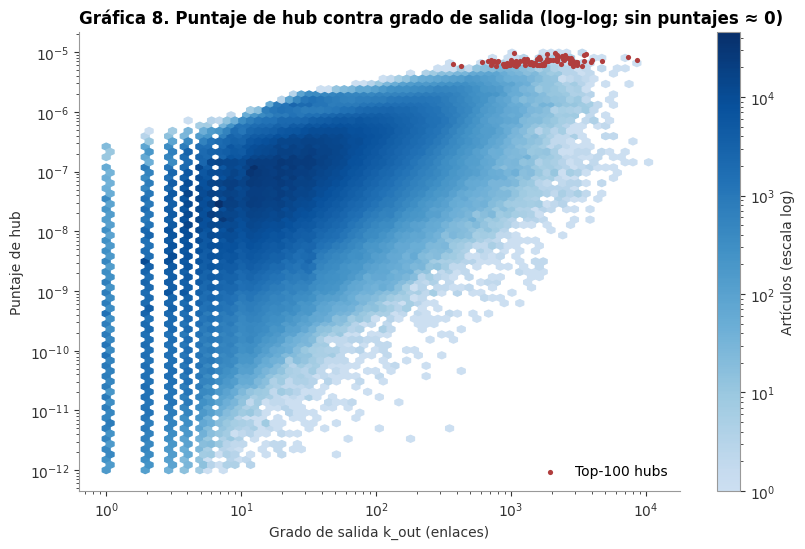

Artículos con hub ≈ 0 (no se grafican): 11,589, de ellos con k_out > 0: 4,032


In [23]:
# Gráfica 8. Puntaje de hub contra grado de salida (log-log)
fig, ax = plt.subplots(figsize=(8.5, 5.6))
con_hub = hubs > CERO
hb = ax.hexbin(k_out_an[con_hub], hubs[con_hub], xscale="log", yscale="log", gridsize=70, bins="log", cmap=CMAP_SEC,
               mincnt=1)
ax.scatter(k_out_an[top_h], hubs[top_h], s=14, color=ROJO, linewidths=0, label="Top-100 hubs")
fig.colorbar(hb, ax=ax, label="Artículos (escala log)")
estilo_ejes(ax, "Gráfica 8. Puntaje de hub contra grado de salida (log-log; sin puntajes ≈ 0)",
            "Grado de salida k_out (enlaces)", "Puntaje de hub", rejilla=None)
ax.legend(loc="lower right")
plt.tight_layout()
archivo_g5 = reg.guardar_figura(fig, "grafica_08_hub_vs_kout", NB)
plt.show()
print(f"Artículos con hub ≈ 0 (no se grafican): {(~con_hub).sum():,}, de ellos con k_out > 0: "
      f"{((~con_hub) & (k_out_an > 0)).sum():,}")
reg.registrar_paso("02.5.2", inicio, [reg.guardar_tabla(tabla_aut, "05_2_top_autoridades", NB),
                                      reg.guardar_tabla(tabla_hubs, "05_2_top_hubs", NB),
                                      reg.guardar_tabla(marcas_top, "05_2_listas_y_cronologias", NB), archivo_g5],
                   f"autoridad 1: {tabla_aut.iloc[0, 0]}; hub 1: {tabla_hubs.iloc[0, 0]}")

**Observaciones.** Los 100 mejores hubs (puntos rojos) están arriba, pero repartidos entre unos 350 y más de 8,000 enlaces de salida. Tener muchos enlaces ayuda, pero no basta: solo 6 de esos 100 están también entre los 100 artículos con más enlaces de salida, y Spearman vale 0.57.

Lo que cuenta es a quién se enlaza. *List of association football stadiums by country* es sexta por enlaces de salida (7,363) y undécima como hub. Hay 4,032 artículos que sí tienen enlaces de salida y aun así tienen un puntaje de hub casi cero, porque no enlazan al bloque que domina el puntaje.

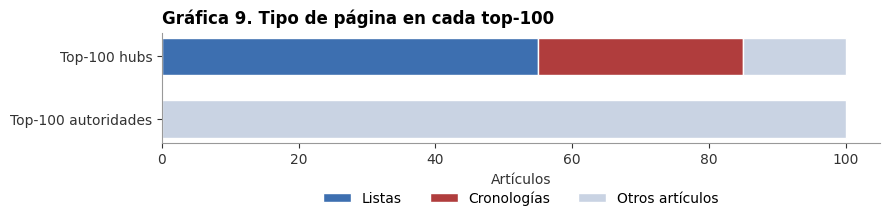

,Listas,Cronologías,Otros artículos
Top-100 hubs,55.0,30.0,15.0
Top-100 autoridades,0.0,0.0,100.0


In [24]:
# Gráfica 9. De qué tipo son los 100 primeros hubs y las 100 primeras autoridades
composicion = pd.DataFrame({"Listas": marcas_top["listas"], "Cronologías": marcas_top["cronologías"]}).iloc[:2]
composicion["Otros artículos"] = 100 - composicion.sum(axis=1)
composicion.index = ["Top-100 hubs", "Top-100 autoridades"]
fig, ax = plt.subplots(figsize=(9, 2.6))
izquierda = np.zeros(2)
for columna, color in zip(composicion.columns, [AZUL, ROJO, "#C9D3E3"]):
    ax.barh(composicion.index[::-1], composicion[columna].to_numpy()[::-1], left=izquierda, color=color, edgecolor="white", label=columna, height=0.6)
    izquierda += composicion[columna].to_numpy()[::-1]
estilo_ejes(ax, "Gráfica 9. Tipo de página en cada top-100", "Artículos", rejilla=None)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=3)
plt.tight_layout()
reg.guardar_figura(fig, "grafica_09_composicion_hits", NB)
plt.show()
display(composicion)

**Observaciones.** Aquí se ve la diferencia entre los dos papeles. De los 100 mejores hubs, 55 son listas y 30 son cronologías, cuando al azar esperaríamos 1.9 y 0.5. Entre las 100 mejores autoridades no hay ninguna de las dos. HITS separó páginas que reúnen enlaces de artículos a los que se apunta, sin saber qué es una lista.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · HITS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">5.2 ¿Quién se lleva el peso en HITS?</span></div>

HITS suele concentrar el puntaje en la comunidad donde muchos hubs enlazan a las mismas autoridades. A esto se le llama **efecto TKC** (*Tightly Knit Community*, comunidad muy unida). Para ver cuál es esa comunidad, medimos cuántos de los enlaces posibles entre los mejores hubs y las mejores autoridades existen de verdad.

In [25]:
# Densidad del bloque top-hubs → top-autoridades y categorías de las top-autoridades
inicio = time.time()
bloque_ha = A_an[top_h][:, top_a]
densidad_global = A_an.nnz / n_an ** 2
top_h1000 = np.argsort(-hubs)[:1000]
recibidos = A_an[:, top_a]
desde_hubs = recibidos[top_h1000].nnz
print(f"Densidad del bloque top-100 hubs → top-100 autoridades: {bloque_ha.nnz / 100 ** 2:.4f} "
      f"(grafo: {densidad_global:.2e}; {bloque_ha.nnz / 100 ** 2 / densidad_global:,.0f} veces mayor)")
print(f"Enlaces que reciben las top-100 autoridades: {recibidos.nnz:,} | desde los top-1,000 hubs: {desde_hubs:,} "
      f"({pct(desde_hubs / recibidos.nnz)}), aunque son el {pct(1000 / n_an, 4)} de los artículos")

ids_top_a = nodos_an.loc[top_a, "id"].to_numpy()
cats_top = (ds.dataset(GRAFO / "categorias_nodo").to_table(filter=ds.field("id").isin(ids_top_a)).to_pandas())
# Sin categorías de mantenimiento («Articles containing…», «Pages with…», «Use dmy dates…»), que no describen el tema
MANTENIMIENTO = r"^(Wikipedia|Articles?\b|All articles|Pages?\b|CS1|Webarchive|Use |Short description|Commons|Good articles|Featured |Coordinates)"
cats_top = cats_top[~cats_top["category"].str.match(MANTENIMIENTO)]
print("Categorías más frecuentes entre las top-100 autoridades (sin categorías de mantenimiento):")
categorias_top = cats_top["category"].value_counts().head(20).rename("autoridades del top-100").to_frame()
display(categorias_top.head(12))
tabla_tkc = pd.Series({"densidad bloque top-100 hubs → top-100 autoridades": bloque_ha.nnz / 100 ** 2,
                       "densidad del grafo": densidad_global,
                       "enlaces que reciben las top-100 autoridades": recibidos.nnz,
                       "de ellos desde los top-1,000 hubs": desde_hubs}, name="valor").to_frame()
reg.registrar_paso("02.5.3", inicio, [reg.guardar_tabla(tabla_tkc, "05_3_tkc", NB),
                                      reg.guardar_tabla(categorias_top, "05_3_categorias_top_autoridades", NB)],
                   f"densidad del bloque {bloque_ha.nnz / 100 ** 2:.4f}")

Densidad del bloque top-100 hubs → top-100 autoridades: 0.3581 (grafo: 4.93e-06; 72,666 veces mayor)
Enlaces que reciben las top-100 autoridades: 6,564,244 | desde los top-1,000 hubs: 27,253 (0.42 %), aunque son el 0.0145 % de los artículos


Categorías más frecuentes entre las top-100 autoridades (sin categorías de mantenimiento):


,autoridades del top-100
category,
Member states of the United Nations,21
OECD members,14
G20 members,14
Countries in Europe,12
Member states of NATO,12
Member states of the Council of Europe,9
Member states of the European Union,8
Member states of the Union for the Mediterranean,8
Podcasting companies,7


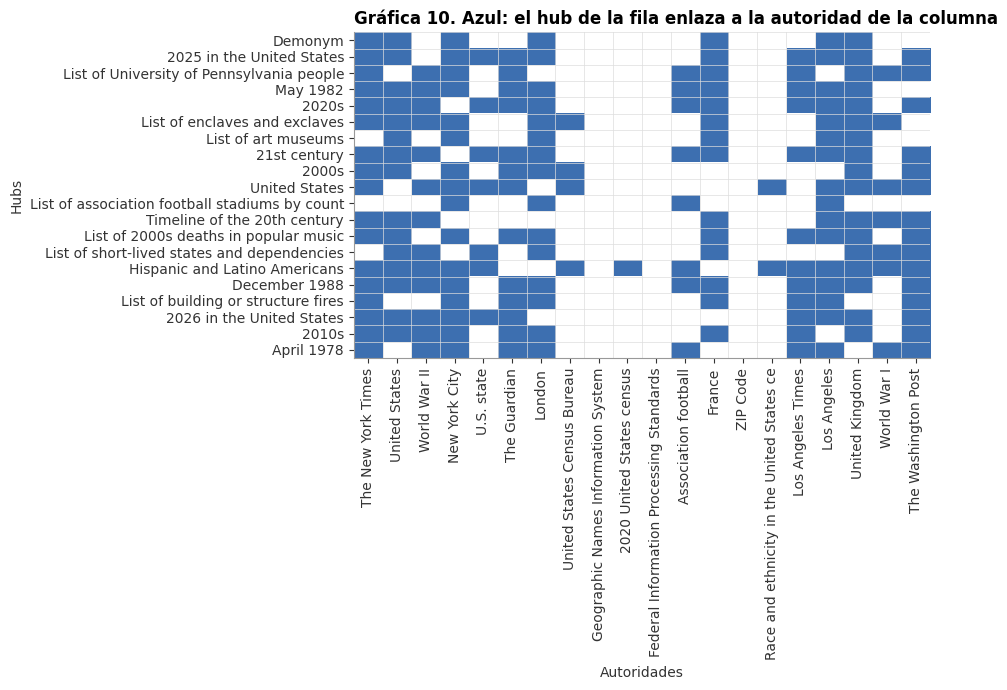

Enlaces presentes en el bloque de 20 × 20: 192 de 400 (48.0%)
Autoridades más enlazadas por estos hubs: ['The New York Times', 'United Kingdom', 'Los Angeles', 'New York City', 'United States']


In [26]:
# Gráfica 10. Enlaces reales entre los 20 primeros hubs y las 20 primeras autoridades
bloque_20 = A_an[top_h[:20]][:, top_a[:20]].toarray()
fig, ax = plt.subplots(figsize=(9.5, 7))
ax.imshow(bloque_20, cmap=LinearSegmentedColormap.from_list("enlace", ["white", AZUL]), aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(20), labels=[t[:42] for t in nodos_an.loc[top_a[:20], "title"]], rotation=90)
ax.set_yticks(range(20), labels=[t[:46] for t in nodos_an.loc[top_h[:20], "title"]])
ax.set_xticks(np.arange(-0.5, 20), minor=True)
ax.set_yticks(np.arange(-0.5, 20), minor=True)
ax.grid(which="minor", color="#DDDDDD", linewidth=0.5)
ax.tick_params(which="minor", length=0)
estilo_ejes(ax, "Gráfica 10. Azul: el hub de la fila enlaza a la autoridad de la columna", "Autoridades", "Hubs", rejilla=None)
plt.tight_layout()
reg.guardar_figura(fig, "grafica_10_bloque_hubs_autoridades", NB)
plt.show()
print(f"Enlaces presentes en el bloque de 20 × 20: {int(bloque_20.sum())} de 400 ({bloque_20.mean():.1%})")
print("Autoridades más enlazadas por estos hubs:", list(nodos_an.loc[top_a[:20][np.argsort(-bloque_20.sum(axis=0))[:5]], "title"]))

**Observaciones.** El 48 % de los cuadros está lleno (192 de 400), y en el bloque de 100 × 100 la densidad es 72,666 veces mayor que en el grafo completo. Ese bloque denso es la comunidad que domina HITS, y no es un tema pequeño: es el núcleo general de países, ciudades, medios y censos de Estados Unidos. Las categorías más frecuentes entre las autoridades lo confirman (21 son *Member states of the United Nations*).

Hay columnas casi vacías, como *Geographic Names Information System*, *2020 United States census* o *ZIP Code*. Son autoridades a las que estos 20 hubs no enlazan. Su puntaje viene de muchas otras páginas, probablemente artículos de localidades de Estados Unidos, aunque no lo comprobamos aquí. Los 1,000 mejores hubs solo dan el 0.42 % de los enlaces que reciben las 100 mejores autoridades.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · HITS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">5.3 PageRank contra HITS</span></div>

Los dos miden importancia por enlaces, pero de distinta forma. PageRank reparte el valor de cada enlace y salta al azar. HITS suma sin repartir y refuerza el bloque más denso. Aquí medimos cuánto coinciden.

,PageRank vs autoridad
Jaccard top-20,0.333
Jaccard top-100,0.449
"Jaccard top-1,000",0.461
Spearman ρ (todos),0.7680
Spearman ρ (solo autoridad > 0),0.7369


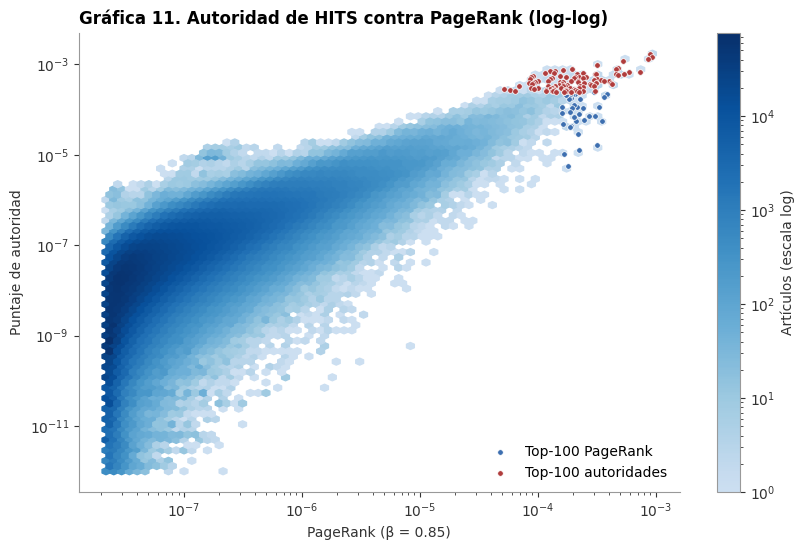

Del top-100 de PageRank, también en el top-100 de autoridades: 62


In [27]:
# Comparación PageRank vs autoridades: traslape, correlación de rangos y Gráfica 11
inicio = time.time()
comparacion_pr_hits = pd.Series({
    "Jaccard top-20": f"{jaccard_top(pr85, autoridades, 20):.3f}",
    "Jaccard top-100": f"{jaccard_top(pr85, autoridades, 100):.3f}",
    "Jaccard top-1,000": f"{jaccard_top(pr85, autoridades, 1000):.3f}",
    "Spearman ρ (todos)": f"{spearmanr(pr85, autoridades).statistic:.4f}",
    "Spearman ρ (solo autoridad > 0)": f"{spearmanr(pr85[autoridades > CERO], autoridades[autoridades > CERO]).statistic:.4f}",
}, name="PageRank vs autoridad").to_frame()
display(comparacion_pr_hits)

fig, ax = plt.subplots(figsize=(8.5, 5.6))
con_aut = autoridades > CERO
hb = ax.hexbin(pr85[con_aut], autoridades[con_aut], xscale="log", yscale="log", gridsize=70, bins="log", cmap=CMAP_SEC,
               mincnt=1)
top_pr = np.argsort(-pr85)[:100]
ax.scatter(pr85[top_pr], np.clip(autoridades[top_pr], CERO, None), s=16, color=AZUL, edgecolors="white", linewidths=0.5,
           label="Top-100 PageRank")
ax.scatter(pr85[top_a], autoridades[top_a], s=16, color=ROJO, edgecolors="white", linewidths=0.5,
           label="Top-100 autoridades")
fig.colorbar(hb, ax=ax, label="Artículos (escala log)")
estilo_ejes(ax, "Gráfica 11. Autoridad de HITS contra PageRank (log-log)", "PageRank (β = 0.85)", "Puntaje de autoridad",
            rejilla=None)
ax.legend(loc="lower right")
plt.tight_layout()
archivo_g6 = reg.guardar_figura(fig, "grafica_11_autoridad_vs_pagerank", NB)
plt.show()
print(f"Del top-100 de PageRank, también en el top-100 de autoridades: {len(np.intersect1d(top_pr, top_a))}")
reg.registrar_paso("02.5.4", inicio, [reg.guardar_tabla(comparacion_pr_hits, "05_4_pagerank_vs_autoridades", NB), archivo_g6],
                   f"Spearman {comparacion_pr_hits.loc['Spearman ρ (todos)', 'PageRank vs autoridad']}; Jaccard top-100 {comparacion_pr_hits.loc['Jaccard top-100', 'PageRank vs autoridad']}")

**Observaciones.** Los dos puntajes van en la misma dirección (Spearman 0.77), pero se separan en lo que más interesa: 62 de los 100 primeros coinciden, y en el top-20 Jaccard vale 0.33.

Los puntos azules son artículos del top-100 de PageRank con mucha menos autoridad: algunos están cerca de $10^{-5}$, cuando las mejores autoridades pasan de $10^{-3}$. PageRank los valora, pero el bloque denso casi no los enlaza. También se nota el salto al azar en el borde izquierdo: PageRank nunca baja de $2.18 \times 10^{-8}$, mientras que la autoridad puede bajar mucho más, porque HITS no reparte nada a quien nadie enlaza.

In [28]:
# Guardado de los puntajes para el notebook 3: PageRank (β = 0.85), hubs y autoridades del grafo de análisis
puntajes = pd.DataFrame({"id": nodos_an["id"], "pagerank": pr85, "hub": hubs, "autoridad": autoridades})
puntajes.to_parquet(ARCHIVO_PUNTAJES, index=False)
print(f"{ARCHIVO_PUNTAJES.name}: {len(puntajes):,} filas, {tamano(ARCHIVO_PUNTAJES.stat().st_size)}")

puntajes.parquet: 6,879,374 filas, 193.9 MB


<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · EXTRAS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">6. Comprobaciones</span></div>

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · EXTRAS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">6.1 ¿Cambia algo por quitar las desambiguaciones?</span></div>

Calculamos PageRank con $\beta = 0.85$ en el grafo completo, con las desambiguaciones, y lo comparamos con el grafo de análisis. Solo comparamos los artículos que están en ambos.

In [29]:
# PageRank sobre el grafo completo y comparación con el grafo de análisis
inicio = time.time()
pr_completo, it_completo = pagerank_potencia(AT_bloques, inv_k_out, beta=0.85)
comun = pr_completo[conserva]   # mismos artículos, en el orden del grafo de análisis
robustez = pd.Series({
    "Iteraciones (completo / análisis)": f"{it_completo} / {filas_pr[1]['iteraciones']}",
    "Masa de PageRank en desambiguaciones (completo)": pct(pr_completo[~conserva].sum()),
    "Desambiguaciones en el top-100 / top-1,000 del completo": f"{(~conserva[np.argsort(-pr_completo)[:100]]).sum()} / "
                                                               f"{(~conserva[np.argsort(-pr_completo)[:1000]]).sum()}",
    "Jaccard top-20": f"{jaccard_top(comun, pr85, 20):.3f}",
    "Jaccard top-100": f"{jaccard_top(comun, pr85, 100):.3f}",
    "Jaccard top-1,000": f"{jaccard_top(comun, pr85, 1000):.3f}",
    "Spearman ρ (artículos comunes)": f"{spearmanr(comun, pr85).statistic:.4f}",
}, name="Valor").rename_axis("PageRank β = 0.85").to_frame()
display(robustez)

cambio = pr85 / (comun / comun.sum()) - 1
casos = pd.DataFrame({"artículo": nodos_an["title"], "k_in": k_in_an, "lugar análisis": lugar_pr,
                      "lugar completo": pd.Series(comun).rank(ascending=False, method="min").astype(int).to_numpy(),
                      "cambio de puntaje": cambio})
print("Del top-1,000 del grafo de análisis, los que más cambian al quitar las desambiguaciones:")
mas_cambian = casos[casos["lugar análisis"] <= 1000].reindex(
    casos.loc[casos["lugar análisis"] <= 1000, "cambio de puntaje"].abs().nlargest(10).index)
display(mas_cambian.head(6).style.format({"cambio de puntaje": "{:+.1%}", "k_in": "{:,}"}))
vector_completo = pd.DataFrame({"id": nodos["id"], "title": nodos["title"], "is_disambig": nodos["is_disambig"],
                                "pagerank_completo": pr_completo})
reg.registrar_paso("02.E2", inicio, [reg.guardar_tabla(robustez, "06_2_robustez", NB),
                                     reg.guardar_tabla(mas_cambian, "06_2_mas_cambian", NB),
                                     reg.guardar_parquet(vector_completo, "06_2_pagerank_grafo_completo", NB)],
                   f"Spearman {robustez.loc['Spearman ρ (artículos comunes)', 'Valor']}")
del AT_bloques   # el grafo completo ya no se usa

,Valor
PageRank β = 0.85,
Iteraciones (completo / análisis),70 / 70
Masa de PageRank en desambiguaciones (completo),0.84 %
"Desambiguaciones en el top-100 / top-1,000 del completo",0 / 0
Jaccard top-20,1.000
Jaccard top-100,0.961
"Jaccard top-1,000",0.986
Spearman ρ (artículos comunes),0.9920


Del top-1,000 del grafo de análisis, los que más cambian al quitar las desambiguaciones:


,artículo,k_in,lugar análisis,lugar completo,cambio de puntaje
indice,,,,,
4082500,Dehestan (administrative division),"51,176.0",240,222,-5.8%
987948,Bakhsh,"54,835.0",121,106,-5.5%
1156209,Counties of Iran,"55,035.0",119,100,-5.5%
171465,Provinces of Iran,"55,136.0",117,98,-5.5%
970998,Iran Standard Time,"55,216.0",127,118,-5.4%
90858,Romanization,"47,318.0",216,203,-5.3%


**Observaciones.** Quitar las desambiguaciones casi no cambia el resultado. El top-20 es idéntico, en el top-100 Jaccard vale 0.961 y Spearman vale 0.992. Ninguna desambiguación llegaba al top-1,000, y entre todas tenían el 0.84 % del PageRank.

Los cambios más grandes son de alrededor de 5 %. Bajan artículos ligados a Irán, como *Bakhsh* y *Counties of Iran*, y suben algunos de insectos, como *Longhorn beetle*. Por eso podemos usar el grafo sin desambiguaciones sin temor a haber cambiado la respuesta.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · EXTRAS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">6.2 ¿Los artículos antiguos tienen ventaja?</span></div>

El dump no trae la fecha de creación, pero el `page_id` crece conforme se crean páginas, así que lo usamos como aproximación. Dividimos los artículos en diez grupos iguales, del `page_id` más bajo al más alto, y vemos cómo se reparte PageRank.

Un resultado aquí no separa la edad del tema: los artículos más antiguos suelen ser también los más generales.

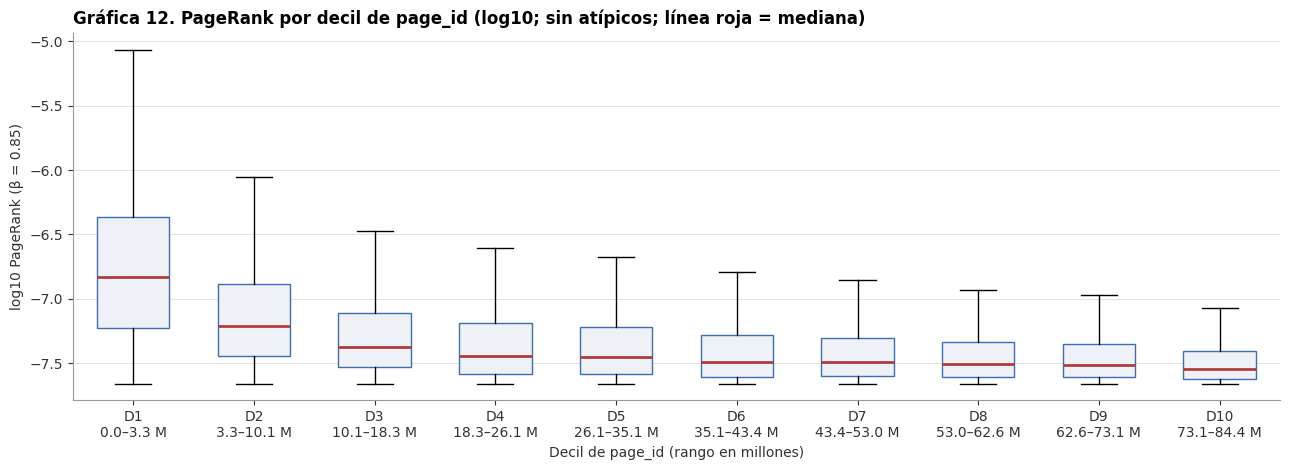

,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10
artículos,687938,687937,687937,687938,687937,687937,687938,687937,687937,687938
PageRank mediano,1.47e-07,6.18e-08,4.23e-08,3.61e-08,3.53e-08,3.21e-08,3.23e-08,3.13e-08,3.07e-08,2.85e-08
% del PageRank total,51.6 %,11.4 %,6.7 %,7.2 %,5.2 %,4.3 %,3.9 %,3.5 %,3.3 %,2.9 %
en el top-100,74,12,3,10,0,0,0,0,1,0
"en el top-10,000",8305,475,212,597,176,104,63,27,22,19


Spearman ρ(PageRank, page_id) = -0.4063


In [30]:
# Gráfica 12. PageRank por decil de page_id
inicio = time.time()
decil = pd.qcut(nodos_an["id"], 10, labels=False).to_numpy()
limites = nodos_an.groupby(decil)["id"].agg(["min", "max"])
etiquetas = [f"D{d + 1}\n{limites.loc[d, 'min'] / 1e6:.1f}–{limites.loc[d, 'max'] / 1e6:.1f} M" for d in range(10)]

fig, ax = plt.subplots(figsize=(13, 4.8))
caja = ax.boxplot([np.log10(pr85[decil == d]) for d in range(10)], positions=range(10), widths=0.6,
                  patch_artist=True, showfliers=False, medianprops=dict(color=ROJO, linewidth=2))
for parche in caja["boxes"]:
    parche.set(facecolor=GRIS_CLARO, edgecolor=AZUL)
ax.set_xticks(range(10), labels=etiquetas)
estilo_ejes(ax, "Gráfica 12. PageRank por decil de page_id (log10; sin atípicos; línea roja = mediana)",
            "Decil de page_id (rango en millones)", "log10 PageRank (β = 0.85)")
plt.tight_layout()
archivo_g4 = reg.guardar_figura(fig, "grafica_12_pagerank_por_decil", NB)
plt.show()

top100 = np.argsort(-pr85)[:100]
por_decil = pd.DataFrame({
    "artículos": pd.Series(decil).value_counts().sort_index(),
    "PageRank mediano": pd.Series(pr85).groupby(decil).median().map(lambda x: f"{x:.2e}"),
    "% del PageRank total": pd.Series(pr85).groupby(decil).sum().map(lambda x: pct(x, 1)),
    "en el top-100": pd.Series(decil[top100]).value_counts().reindex(range(10), fill_value=0),
    "en el top-10,000": pd.Series(decil[np.argsort(-pr85)[:10_000]]).value_counts().reindex(range(10), fill_value=0),
})
por_decil.index = [f"D{d + 1}" for d in range(10)]
display(por_decil.T)
rho_id = spearmanr(pr85, nodos_an["id"]).statistic
print(f"Spearman ρ(PageRank, page_id) = {rho_id:.4f}")
reg.registrar_paso("02.E3", inicio, [archivo_g4, reg.guardar_tabla(por_decil, "06_3_pagerank_por_decil", NB)],
                   f"Spearman ρ(PageRank, page_id) = {rho_id:.4f}")

**Observaciones.** El primer grupo (`page_id` hasta 3.3 millones) tiene el 51.6 % de todo el PageRank y 74 de los 100 primeros. Su mediana es unas 5 veces la del último grupo, y Spearman entre PageRank y `page_id` vale −0.41.

Hay dos lecturas posibles y esta gráfica no las separa: los artículos antiguos tuvieron más tiempo para recibir enlaces, y también suelen ser los temas más generales, que se escribieron primero.

In [31]:
POOL.shutdown()

Las conclusiones de toda la práctica están al final de `04_recomendaciones.ipynb`.